# Climate Sensitivity Analysis for a Maize Farming Enterprise
### From rainfall shocks to cash flow: a case project in the agriculture sector

**Course link:** Climate Vulnerability and Risk Assessment, *Module 4: Risk Assessment Frameworks* (sensitivity analysis approaches, risk quantification models), with links to Module 8 (sectoral sensitivity), Module 10 (uncertainty analysis, scenario-based modeling) and Module 15 (damage and loss estimation, cost-benefit of adaptation).

---

## 1. The case

A commercial maize enterprise farms **500 ha** of rain-fed land in a semi-humid county in Kenya. It borrowed to buy equipment and has to make a **fixed annual loan repayment**. The lender asks one question:

> *How sensitive is the farm's cash flow, and its ability to repay the loan, to drought and heat, and what should we do about it?*

Maize is the staple crop and is highly sensitive to rainfall shortfalls during the long-rains season, so this is a realistic agriculture-sector risk question.

## 2. Objectives

1. Build a chain that links **climate hazard → yield loss → financial impact** (revenue, operating cash flow, debt service coverage).
2. Run **three kinds of sensitivity analysis**, from simple to advanced:
   - *Deterministic / scenario* sensitivity and a **breaking point** (stress-test style).
   - *One-at-a-time (local)* sensitivity with a **tornado chart**.
   - *Global* sensitivity using **Monte Carlo** simulation and **Sobol variance-based indices**.
3. Compare **adaptation options** (drought-tolerant seed, index insurance) and see how they change risk.
4. Interpret results and state limitations honestly.

## 3. Workflow

| Step | What we do | Method |
|---|---|---|
| 1 | Set up libraries and the farm's baseline financials | Baseline model |
| 2 | Create illustrative climate and yield data | Synthetic data |
| 3 | Estimate how yield responds to rainfall deficit and heat | Regression (damage function) |
| 4 | Build the climate-to-cash-flow model | Risk quantification model |
| 5 | Check the baseline | Validation |
| 6 | Scenario sensitivity and breaking point | Deterministic / stress test |
| 7 | One-at-a-time sensitivity | Tornado chart |
| 8 | Two-way sensitivity | Heatmap |
| 9 | Monte Carlo simulation | Probabilistic risk |
| 10 | Global sensitivity | Rank correlation and Sobol indices |
| 11 | Stress test and adaptation options | Scenario comparison |
| 12 | Findings, limitations, extensions | Interpretation |

## 4. Important note on the data

This version reads its data from **two CSV files** that sit next to the notebook:

- `climate_monthly_2020_2025_synthetic.csv`: **monthly** rainfall (`PRECTOTCORR`, mm/day) and 2 m temperature (`T2M`, °C) for one point, January 2020 to December 2025 (72 rows).
- `maize_yield_2020_2025_synthetic.csv`: one maize yield (t/ha) per long-rains season, 2020 to 2025 (6 rows).

**Both files are illustrative (synthetic).** They are laid out like NASA POWER output so you can later swap in real downloads without changing the code. The **farm financials in `BASE` (Step 1) are also illustrative**. Replace them with the real farm's numbers before drawing any conclusions.

**Important:** six seasons is a *very* short record. The notebook warns you about this and Step 3b measures how uncertain the fitted damage function is. Treat the results as a demonstration of the method, not as a finding about a real farm.

You can still use `DATA_MODE = "synthetic"` (35 generated seasons, offline) or `"nasa_power"` (live daily download) by changing the settings in Step 2.

Money is in **Kenya shillings (KES)**, shown in millions (M) where helpful.

---
## Step 1: Setup and baseline farm financials

**What this step does:** imports the libraries and defines the farm's baseline numbers in one dictionary, `BASE`. Keeping all assumptions in one place makes the sensitivity work easy later, because we can change one value and re-run the model.

**Libraries used**
- `numpy`, `pandas`: calculations and tables
- `matplotlib`: charts
- `scipy`: distribution fitting and root finding (for the breaking point)
- `SALib`: global sensitivity analysis (Sobol). If it is missing, uncomment the `%pip` line in the next cell.

**Real-data note:** the values in `BASE` are placeholders. Replace them with the real enterprise's figures: area and yield from farm records, price from NCPB or market data, and costs from farm accounts or county gross-margin budgets (the Ministry of Agriculture and KALRO publish typical maize budgets). Loan terms come from the lender.

**Baseline logic**
- Revenue = yield (t/ha) × area (ha) × price (KES/t)
- Operating cash flow (OCF) = revenue − variable costs − fixed costs
- DSCR (debt service coverage ratio) = OCF ÷ loan repayment. A DSCR below **1.0** means the farm cannot cover the repayment from operations. Lenders usually want about 1.2 or more.

In [1]:
# =============================================================================
# STEP 1: SETUP -- libraries, display settings and the farm's baseline numbers
# =============================================================================
# %pip install SALib      # uncomment if SALib is not installed (it is needed for the Sobol analysis in Step 10)

import numpy as np                      # fast maths on arrays of numbers
import pandas as pd                     # tables (DataFrames)
import matplotlib.pyplot as plt         # charts
from scipy import stats                 # statistical distributions (gamma) and rank correlations
from scipy.optimize import brentq       # root finder: used to locate "breaking points"

from SALib.sample import sobol as sobol_sample      # builds the input samples needed for Sobol analysis
from SALib.analyze import sobol as sobol_analyze    # turns the model results into Sobol sensitivity indices

# Reproducibility: a fixed seed means the "random" numbers are identical every time you run the notebook.
SEED = 42
rng = np.random.default_rng(SEED)       # the random number generator used throughout

# Chart appearance (cosmetic only)
plt.rcParams.update({
    "figure.dpi": 110,                  # sharper charts
    "axes.spines.top": False,           # remove the top and right chart borders
    "axes.spines.right": False,
    "axes.grid": True,                  # light grid lines
    "grid.alpha": 0.25,
    "font.size": 10,
})
pd.options.display.float_format = "{:,.2f}".format   # show numbers with 2 decimals and thousands separators
M = 1e6                                               # divide KES by M to show millions

# ----- Baseline assumptions for the farm (ILLUSTRATIVE: replace with the real farm's numbers) -----
BASE = {
    "area_ha": 500,              # cultivated area (hectares)
    "base_yield": 3.0,           # yield in a normal season (t/ha)
    "price": 45_000,             # crop price (KES per tonne)
    "var_cost_ha": 60_000,       # variable costs: seeds, fertiliser, labour... (KES per ha)
    "fixed_cost": 15_000_000,    # overheads, depreciation, management (KES per year)
    "loan": 12_000_000,          # annual loan repayment (KES per year)

    # Index insurance (used later in Step 11)
    "ins_premium": 2_000_000,    # annual premium (KES)
    "ins_trigger1": 0.20,        # payout tier 1 pays if the rainfall deficit exceeds 20%
    "ins_payout1": 6_000_000,    # size of the tier 1 payout (KES)
    "ins_trigger2": 0.30,        # payout tier 2 pays if the rainfall deficit exceeds 30%
    "ins_payout2": 12_000_000,   # size of the tier 2 payout (KES)
}

pd.Series(BASE).to_frame("value")        # display the assumptions as a table

,value
area_ha,500.00
base_yield,3.00
price,"45,000.00"
var_cost_ha,"60,000.00"
fixed_cost,"15,000,000.00"
loan,"12,000,000.00"
ins_premium,"2,000,000.00"
ins_trigger1,0.20
ins_payout1,"6,000,000.00"
ins_trigger2,0.30


---
## Step 2: Load the climate and yield data (real or illustrative)

**What this step does:** builds the three yearly series that the damage function needs, one value per growing season:

1. **Seasonal rainfall** (mm)
2. **Seasonal mean temperature**, converted to an *anomaly* (difference from the long-term mean)
3. **Crop yield** (t/ha), converted to a *yield ratio* (actual yield ÷ its long-term trend)

Everything after this step uses only those series, so you can switch between real and illustrative data by changing the settings in the next cell.

### Climate data modes (`DATA_MODE`)

| Mode | Source | Notes |
|---|---|---|
| `"nasa_power"` | NASA POWER API: daily rainfall and temperature for a point you choose | Free, no account, needs internet. Grid is coarse (about 0.5° × 0.625°), so it smooths local rainfall. Good for learning and screening. |
| `"csv"` | Your own file: **monthly** (`year, month, PRECTOTCORR, T2M`), **daily** (`date, rain_mm, temp_c`) or **seasonal** (`year, rain_mm, temp_c`) | Use this for NASA POWER downloads, CHIRPS extracts, Kenya Meteorological Department station data, or any dataset you prefer. Temperature is optional. **This is the default mode in this version of the notebook.** |
| `"synthetic"` | Generated | The original illustrative data. Works offline. |

### The monthly file format (the default here)

| Column | Meaning | Unit |
|---|---|---|
| `year` | Calendar year | |
| `month` | Month number, 1 to 12 | |
| `PRECTOTCORR` | Mean daily rainfall in that month (NASA POWER's bias-corrected precipitation) | **mm per day** |
| `T2M` | Mean 2 m air temperature in that month | °C |

The notebook turns this into one value per growing season in two simple steps:
1. **Rainfall:** monthly total = `PRECTOTCORR` × days in the month (so February in a leap year counts 29 days). The season's rainfall is the sum of its months, for example March + April + May.
2. **Temperature:** the season's temperature is the average of its months, weighted by the number of days in each month.

Columns named `rain_mm` (a *monthly total* in mm) and `temp_c` are also accepted, so you can use your own file layout.

### Yield data (`YIELD_CSV`)
A CSV with two columns, `year` and `yield_t_ha`. If you leave it as `None`, the notebook creates **synthetic yields and prints a warning**, so you can still run everything while you look for data.

Possible sources for maize yields: county agriculture office annual reports, the KNBS *Economic Survey* and *Statistical Abstract*, the Ministry of Agriculture's data, or FAOSTAT for national yields (FAOSTAT reports hg/ha, so **divide by 10,000** to get t/ha). County or farm-level data is better than national data for a local case.

### Things that matter when you use real data
1. **Match the season to the crop.** Kenya's long rains are roughly March–May and short rains roughly October–December. Set `SEASON_MONTHS` for the season your crop actually grows in.
2. **Detrend yields.** Yields usually rise over time because of better seed and practices, which has nothing to do with climate. Dividing by a trend line isolates the climate-driven variation. Note that warming and technology trends can overlap, so the temperature effect is the hardest to separate.
3. **Match the geography.** Use the coordinates of your actual case area, and be aware that gridded rainfall may not match a single farm.
4. **Check how many years you have.** Fewer than about 15 overlapping years, or very few drought years, gives an unreliable fit. The notebook warns you. **This version of the notebook uses only 6 seasons, so expect those warnings.** With so few points, trend removal is switched off (`DETREND_YIELDS = False`) because a trend line fitted to six points would mostly absorb the climate signal.
5. **Look at the scatter plot.** Yields can also fall in very *wet* years (waterlogging, disease). This model only represents drought, and the diagnostic plot below helps you spot when that is not enough.

In [2]:
# =============================================================================
# STEP 2a: CONFIGURE YOUR DATA HERE  (the only cell you normally need to edit)
# =============================================================================

# Where does the climate data come from?
#   "csv"        -> read the files named below (monthly, daily or seasonal)   <- default in this version
#   "nasa_power" -> download DAILY data live from NASA POWER (needs internet)
#   "synthetic"  -> generate 35 illustrative seasons offline
DATA_MODE = "csv"

# Only used when DATA_MODE = "nasa_power": the point to download and the years to fetch.
LAT, LON = -1.52, 37.26            # latitude, longitude in decimal degrees (example point only)
START_YEAR, END_YEAR = 1991, 2024  # NASA POWER daily data starts in 1981

# Months that make up the growing season (3, 4, 5 = March-May = Kenya's long rains).
# Rainfall is SUMMED over these months and temperature is AVERAGED over them.
SEASON_MONTHS = [3, 4, 5]

# Climate file for DATA_MODE = "csv". Monthly layout: year, month, PRECTOTCORR (mm/day), T2M (deg C)
CLIMATE_CSV = "climate_monthly_2020_2025_synthetic.csv"

# Yield file: columns year, yield_t_ha (one row per season). Set to None to use synthetic yields (a warning is printed).
YIELD_CSV = "maize_yield_2020_2025_synthetic.csv"

# Remove the long-run trend from yields (technology and management improvements)?
# False here: with only 6 seasons a trend line would absorb the climate signal.
DETREND_YIELDS = False

# --- Google Colab: to upload the two CSV files, uncomment these two lines, run the cell and pick both files ---
# from google.colab import files
# uploaded = files.upload()

In [3]:
# =============================================================================
# STEP 2b: HELPER FUNCTIONS for loading and preparing the data
# =============================================================================

def load_nasa_power(lat, lon, y0, y1):
    # Download DAILY rainfall (PRECTOTCORR, mm/day) and 2 m temperature (T2M, deg C) for one point
    # from the NASA POWER API. Only used when DATA_MODE = "nasa_power".
    import requests
    url = "https://power.larc.nasa.gov/api/temporal/daily/point"
    params = {"parameters": "PRECTOTCORR,T2M", "community": "AG",       # AG = agroclimatology community
              "longitude": lon, "latitude": lat,
              "start": f"{y0}0101", "end": f"{y1}1231", "format": "JSON"}
    resp = requests.get(url, params=params, timeout=180)
    resp.raise_for_status()                                             # stop with a clear error if the request failed
    par = resp.json()["properties"]["parameter"]                        # {"PRECTOTCORR": {date: value}, "T2M": {...}}
    daily = pd.DataFrame({"rain_mm": par["PRECTOTCORR"], "temp_c": par["T2M"]})   # a daily rate in mm/day IS the daily total in mm
    daily.index = pd.to_datetime(daily.index, format="%Y%m%d")          # turn "20200301" into a real date
    return daily.replace(-999, np.nan)                                  # NASA POWER uses -999 for missing values


def load_climate_csv(path):
    # Read a climate CSV and work out its time step. Returns (table, step) where step is
    # "monthly", "daily" or "seasonal". Accepted layouts:
    #   monthly : year, month, PRECTOTCORR (mm/day) or rain_mm (monthly total mm), T2M or temp_c
    #   daily   : date, rain_mm (or PRECTOTCORR), temp_c (or T2M)
    #   seasonal: year, rain_mm, temp_c
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]               # ignore capital letters and stray spaces

    # Temperature is optional: accept either name, otherwise leave it empty
    if "temp_c" not in df.columns:
        df["temp_c"] = df["t2m"] if "t2m" in df.columns else np.nan

    if "date" in df.columns:                                           # ---- DAILY file ----
        if "rain_mm" not in df.columns:
            df["rain_mm"] = df["prectotcorr"] if "prectotcorr" in df.columns else np.nan   # mm/day = mm for that day
        df["date"] = pd.to_datetime(df["date"])
        return df.set_index("date")[["rain_mm", "temp_c"]].sort_index(), "daily"

    if "year" in df.columns and "month" in df.columns:                 # ---- MONTHLY file ----
        dates = pd.to_datetime(dict(year=df["year"], month=df["month"], day=1))   # first day of each month
        days = dates.dt.days_in_month.values                           # 28, 29, 30 or 31 (handles leap years)
        if "rain_mm" in df.columns:
            rain_total = df["rain_mm"].values                          # already a monthly total in mm
        elif "prectotcorr" in df.columns:
            rain_total = df["prectotcorr"].values * days               # mm per day x days in month = monthly total (mm)
        else:
            rain_total = np.full(len(df), np.nan)
        out = pd.DataFrame({"rain_mm": rain_total, "temp_c": df["temp_c"].values}, index=pd.DatetimeIndex(dates))
        out.index.name = "date"
        return out.sort_index(), "monthly"

    if "year" in df.columns:                                           # ---- SEASONAL file ----
        if "rain_mm" not in df.columns:
            df["rain_mm"] = np.nan
        df["year"] = df["year"].astype(int)
        return df.set_index("year")[["rain_mm", "temp_c"]].sort_index(), "seasonal"

    raise ValueError("Climate CSV needs a 'date' column (daily), 'year' and 'month' columns (monthly), "
                     "or a 'year' column (seasonal).")


def monthly_to_seasonal(monthly, months):
    # Turn monthly data into one row per year: rainfall = SUM of the season's months,
    # temperature = AVERAGE of the season's months weighted by days in each month.
    # A year is kept only if EVERY month of the season is present.
    m = monthly[monthly.index.month.isin(months)].copy()               # keep only the season's months
    m["days"] = m.index.days_in_month                                  # days in each month, used as weights
    yr = m.index.year
    n_present = m["rain_mm"].groupby(yr).count()                       # how many season months have rainfall data
    rain = m["rain_mm"].groupby(yr).sum(min_count=1)                   # season rainfall total (mm)
    wt_temp = (m["temp_c"] * m["days"]).groupby(yr).sum(min_count=1)   # sum of temperature x days
    wt_days = m["days"].where(m["temp_c"].notna()).groupby(yr).sum(min_count=1)   # days that actually have a temperature
    out = pd.DataFrame({"rain_mm": rain, "temp_c": wt_temp / wt_days})
    out = out[n_present == len(months)]                                # drop incomplete seasons
    out.index.name = "year"
    return out


def to_seasonal(daily, months, min_cover=0.9):
    # Turn DAILY data into one row per year: rainfall = season total, temperature = season mean.
    # A year is kept only if at least `min_cover` (90%) of the season's days have data.
    d = daily[daily.index.month.isin(months)]                          # keep only days in the season's months
    yr = d.index.year
    expected = pd.Series({y: sum(pd.Period(f"{y}-{m:02d}").days_in_month for m in months)
                          for y in np.unique(yr)})                     # how many days each season should have
    cover = d["rain_mm"].groupby(yr).count() / expected                # share of days with a rainfall value
    out = pd.DataFrame({"rain_mm": d["rain_mm"].groupby(yr).sum(min_count=1) / cover,   # scale up if a few days are missing
                        "temp_c": d["temp_c"].groupby(yr).mean()})
    out = out[cover >= min_cover]
    out.index.name = "year"
    return out


def load_yields(path):
    # Read a yield file with columns: year, yield_t_ha. Returns a Series indexed by year.
    y = pd.read_csv(path)
    y.columns = [c.strip().lower() for c in y.columns]
    y = y.rename(columns={"yield": "yield_t_ha"})                      # accept a column simply called "yield"
    y = y[["year", "yield_t_ha"]].dropna()
    y["year"] = y["year"].astype(int)
    return y.set_index("year")["yield_t_ha"].sort_index()


def make_synthetic_climate(rng, years):
    # Illustrative seasonal climate for DATA_MODE = "synthetic": gamma rainfall (mean 450 mm, CV 20%) plus warming.
    n = len(years)
    shape = 1 / 0.20**2                                                # gamma shape from the coefficient of variation
    rain = rng.gamma(shape, 450 / shape, size=n)
    temp = 20.0 + (-0.4 + 0.025 * (years - years[0]) + rng.normal(0, 0.3, n))   # slow warming trend plus noise
    return pd.DataFrame({"rain_mm": rain, "temp_c": temp}, index=pd.Index(years, name="year"))


def make_synthetic_yields(rng, clim, rain_ref, temp_ref, base_yield):
    # Illustrative yields used when no yield file is supplied: a hidden damage relationship plus noise.
    d = np.maximum(0, (rain_ref - clim["rain_mm"]) / rain_ref)         # rainfall deficit
    t = clim["temp_c"] - temp_ref                                      # temperature anomaly
    loss = 0.20 * d + 2.0 * d**2 + 0.03 * t                            # "true" fractional loss
    ratio = 1 - loss + rng.normal(0, 0.03, len(clim))                  # yield ratio with random noise
    return (base_yield * ratio).rename("yield_t_ha")

print("Helper functions defined.")

Helper functions defined.


In [4]:
# =============================================================================
# STEP 2c: BUILD THE YEARLY SERIES (one value per growing season)
# =============================================================================
YIELDS_SYNTHETIC = False     # becomes True if we have to invent yields
monthly_raw = None           # keeps the monthly table (if any) so we can display it below

# 1) Seasonal climate for every available year ---------------------------------
if DATA_MODE == "nasa_power":
    try:
        daily = load_nasa_power(LAT, LON, START_YEAR, END_YEAR)
    except Exception as e:                                             # explain failures instead of a cryptic crash
        raise RuntimeError(
            "NASA POWER download failed: " + str(e) + "  -> Check your internet connection and the "
            "LAT/LON values, or set DATA_MODE to 'csv' (your own file) or 'synthetic'.")
    clim = to_seasonal(daily, SEASON_MONTHS)

elif DATA_MODE == "csv":
    if CLIMATE_CSV is None:
        raise ValueError("DATA_MODE is 'csv' but CLIMATE_CSV is None. Set the file path in the config cell.")
    raw, step = load_climate_csv(CLIMATE_CSV)                          # also tells us if the file is monthly/daily/seasonal
    if step == "monthly":
        monthly_raw = raw
        clim = monthly_to_seasonal(raw, SEASON_MONTHS)
    elif step == "daily":
        clim = to_seasonal(raw, SEASON_MONTHS)
    else:
        clim = raw                                                     # already one row per season
    print(f"Loaded {step} climate data from {CLIMATE_CSV}: {len(raw)} rows -> {len(clim)} seasons.")

elif DATA_MODE == "synthetic":
    clim = make_synthetic_climate(rng, np.arange(1990, 2025))

else:
    raise ValueError("DATA_MODE must be 'nasa_power', 'csv' or 'synthetic'.")

# Long-term reference values come from the FULL climate record ------------------
rain_full = clim["rain_mm"].dropna()                  # one seasonal rainfall total per year
rain_ref = rain_full.mean()                           # "normal" seasonal rainfall (long-term mean)
HAS_TEMP = clim["temp_c"].notna().any()               # did we get temperature data?
temp_ref = clim["temp_c"].mean() if HAS_TEMP else 0.0 # "normal" seasonal temperature

clim["temp_anom"] = (clim["temp_c"] - temp_ref) if HAS_TEMP else 0.0                    # degrees warmer than normal
clim["deficit"] = np.maximum(0, (rain_ref - clim["rain_mm"]) / rain_ref)                # fraction below normal rainfall (0 if wetter)

# 2) Yields --------------------------------------------------------------------
if YIELD_CSV is not None:
    yld = load_yields(YIELD_CSV)                      # real (or supplied) yields
else:
    YIELDS_SYNTHETIC = True
    yld = make_synthetic_yields(rng, clim, rain_ref, temp_ref, BASE["base_yield"])

# 3) Keep only years that have BOTH climate and yield data ---------------------
data = clim.join(yld.rename("yield_t_ha"), how="inner").dropna(subset=["rain_mm", "yield_t_ha"])

# 4) Detrend yields (remove the steady rise from better seed and management) ---
#    Skipped for synthetic yields, when DETREND_YIELDS is False, or when there are too few years for a trend.
if DETREND_YIELDS and not YIELDS_SYNTHETIC and len(data) >= 8:
    trend_coef = np.polyfit(data.index.values.astype(float), data["yield_t_ha"].values, 1)     # straight-line trend
    data["yield_trend"] = np.polyval(trend_coef, data.index.values.astype(float))
else:
    data["yield_trend"] = data["yield_t_ha"].mean()                    # "trend" is just the average yield
data["yield_ratio"] = data["yield_t_ha"] / data["yield_trend"]         # ~1.0 normally, below 1.0 in bad years

# 5) Arrays used by the rest of the notebook -----------------------------------
years = data.index.values
n = len(data)                                         # number of seasons used to fit the damage function
rain = data["rain_mm"].values
temp_anom = data["temp_anom"].values
deficit = data["deficit"].values
yield_ratio = data["yield_ratio"].values

hist = pd.DataFrame({                                 # tidy table for display and charts
    "rain_mm": rain, "temp_anom_C": temp_anom, "deficit": deficit,
    "yield_ratio": yield_ratio, "yield_t_ha": data["yield_t_ha"].values,
}, index=pd.Index(years, name="year"))

display(hist.head(8))

Loaded monthly climate data from climate_monthly_2020_2025_synthetic.csv: 72 rows -> 6 seasons.


,rain_mm,temp_anom_C,deficit,yield_ratio,yield_t_ha
year,,,,,
2020,505.03,-0.16,0.00,1.08,2.95
2021,300.01,0.24,0.33,0.74,2.01
2022,354.98,-0.06,0.20,1.00,2.72
2023,470.01,-0.36,0.00,1.06,2.90
2024,649.99,0.21,0.00,1.12,3.05
2025,395.02,0.13,0.11,1.01,2.76


In [5]:
# ---------- Data quality checks: print what we loaded and warn about weaknesses ----------
print(f"Data mode: {DATA_MODE}")
print(f"Climate record: {len(rain_full)} seasons ({rain_full.index.min()}-{rain_full.index.max()}), "
      f"season months {SEASON_MONTHS}")
print(f"Seasonal rainfall: mean {rain_ref:.0f} mm, coefficient of variation {rain_full.std() / rain_ref:.0%}")
print(f"Years used to fit the damage function (climate and yields overlap): {n}")
print(f"Years with a rainfall deficit in that sample: {(deficit > 0).sum()} of {n}; "
      f"worst deficit {deficit.max():.0%}")

if not HAS_TEMP:
    print("NOTE: no temperature data, so the temperature effect is set to zero.")
if YIELDS_SYNTHETIC:
    print("WARNING: yields are SYNTHETIC. Climate may be real, but the damage function below will only "
          "recover the illustrative relationship. Supply YIELD_CSV for a real result.")
else:
    print(f"Average yield in the sample is about {data['yield_trend'].iloc[-1]:.2f} t/ha. "
          f"Step 3 reports the implied normal-year yield; compare it with BASE['base_yield'] ({BASE['base_yield']} t/ha) and adjust BASE if your farm differs.")

# Warnings about a short record (these will appear with the 6-season dataset)
if n < 15:
    print(f"WARNING: only {n} overlapping years. Treat the fitted damage function as very uncertain (see Step 3b).")
if len(rain_full) < 15:
    print(f"WARNING: the climate record has only {len(rain_full)} seasons, so the long-term mean and the rainfall "
          "distribution used in Step 9 are poorly estimated.")
if (deficit > 0.10).sum() < 4:
    print("WARNING: fewer than 4 years with a deficit above 10%. There is little drought signal to learn from.")

Data mode: csv
Climate record: 6 seasons (2020-2025), season months [3, 4, 5]
Seasonal rainfall: mean 446 mm, coefficient of variation 28%
Years used to fit the damage function (climate and yields overlap): 6
Years with a rainfall deficit in that sample: 3 of 6; worst deficit 33%
Average yield in the sample is about 2.73 t/ha. Step 3 reports the implied normal-year yield; compare it with BASE['base_yield'] (3.0 t/ha) and adjust BASE if your farm differs.



**Look inside the monthly data.** The table shows the monthly rainfall (mm) for each year, with the **Season total** column being the number the notebook uses (the sum of the growing-season months). The chart shows the shape of the year: the two rainy seasons and the dry middle of the year. The shaded band is the growing season.


month,1,2,3,4,5,6,7,8,9,10,11,12,Season total
year,,,,,,,,,,,,,
2020,37.00,19.10,88.00,252.80,164.20,32.70,11.50,22.00,32.00,83.10,126.00,100.70,505.00
2021,47.90,35.50,80.50,150.00,69.50,69.90,11.90,31.10,13.90,65.20,81.80,85.60,300.00
2022,72.10,56.30,112.60,120.10,122.30,23.10,14.20,21.00,26.90,79.20,177.30,76.50,355.00
2023,39.90,54.90,127.00,221.80,121.20,29.60,21.90,9.10,31.00,32.20,132.40,33.60,470.00
2024,59.20,60.40,173.20,204.30,272.50,30.60,28.10,19.80,16.80,49.50,97.90,81.50,650.00
2025,94.70,24.20,101.20,164.10,129.70,20.60,21.50,13.80,35.90,64.60,110.00,74.80,395.00


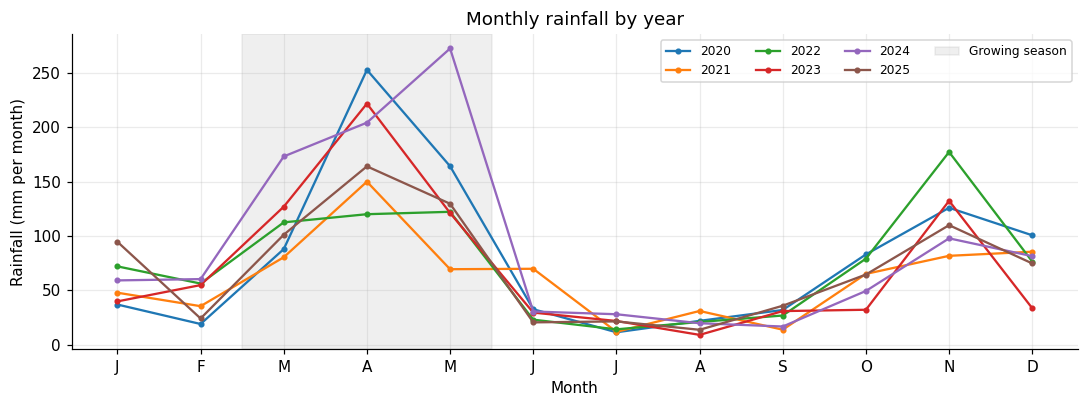

In [6]:

# ---------- Look inside the monthly data (runs only when a monthly file was loaded) ----------
if monthly_raw is not None:
    m_tab = monthly_raw.copy()
    m_tab["year"], m_tab["month"] = m_tab.index.year, m_tab.index.month
    # Rows = years, columns = months 1..12, values = monthly rainfall total (mm)
    rain_tab = m_tab.pivot(index="year", columns="month", values="rain_mm")
    rain_tab["Season total"] = rain_tab[SEASON_MONTHS].sum(axis=1)       # the value used by the notebook
    display(rain_tab.round(1))

    fig, ax = plt.subplots(figsize=(10, 3.8))
    for yr_, row in rain_tab.drop(columns="Season total").iterrows():
        ax.plot(row.index, row.values, marker="o", ms=3, label=str(yr_))   # one line per year
    ax.axvspan(min(SEASON_MONTHS) - 0.5, max(SEASON_MONTHS) + 0.5, color="grey", alpha=0.12, label="Growing season")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
    ax.set(xlabel="Month", ylabel="Rainfall (mm per month)", title="Monthly rainfall by year")
    ax.legend(ncol=4, fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No monthly file was loaded, so there is no monthly table to show.")


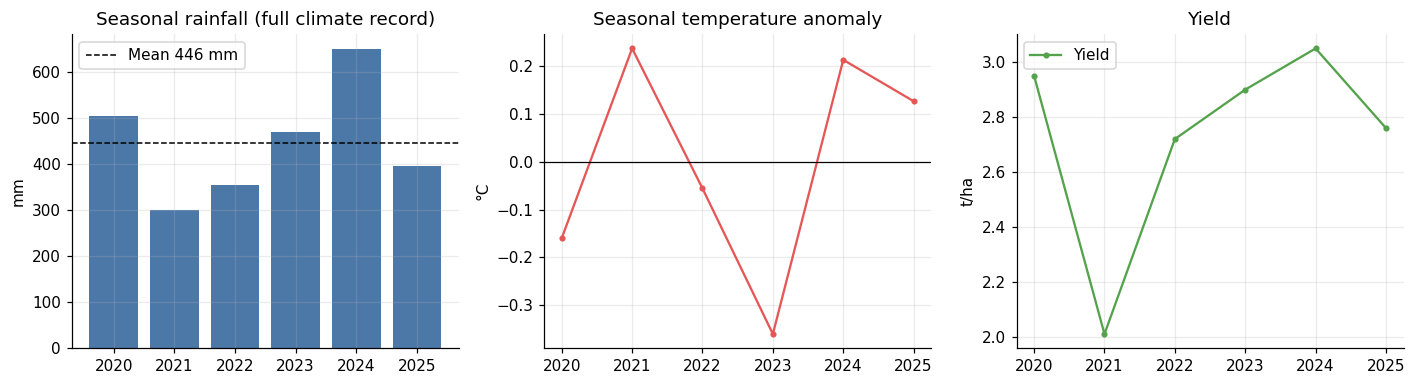

In [7]:
# ---------- Three panels: rainfall, temperature anomaly and yield for each season ----------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# Panel 1: seasonal rainfall as bars, with the long-term mean as a dashed line
axes[0].bar(rain_full.index, rain_full.values, color="#4C78A8")
axes[0].axhline(rain_ref, color="k", ls="--", lw=1, label=f"Mean {rain_ref:.0f} mm")
axes[0].set(title="Seasonal rainfall (full climate record)", ylabel="mm"); axes[0].legend()

# Panel 2: seasonal temperature anomaly (degrees above or below the record average)
if HAS_TEMP:
    axes[1].plot(clim.index, clim["temp_anom"], color="#E45756", marker="o", ms=3)
    axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="Seasonal temperature anomaly", ylabel="°C")

# Panel 3: yields (and the trend line if yields were detrended)
axes[2].plot(hist.index, hist["yield_t_ha"], color="#54A24B", marker="o", ms=3, label="Yield")
if not YIELDS_SYNTHETIC and DETREND_YIELDS:
    axes[2].plot(data.index, data["yield_trend"], color="k", ls="--", lw=1, label="Trend")
axes[2].set(title="Yield" + (" (synthetic)" if YIELDS_SYNTHETIC else ""), ylabel="t/ha"); axes[2].legend()

for a in axes:                                        # whole-year ticks only (avoid 2020.5 on the x-axis)
    a.xaxis.get_major_locator().set_params(integer=True)

plt.tight_layout(); plt.show()

**Diagnostic plot: does drought explain the yield variation?**

The next chart plots the yield ratio against the rainfall departure (negative = drier than normal). Check for these patterns:
- **Yield ratio falls on the left (dry years):** good, the drought damage function is appropriate.
- **Yield ratio also falls on the far right (very wet years):** there are wet-year losses (waterlogging, disease, flooding) that this model does not represent. Mention this as a limitation, or extend the model.
- **No visible pattern:** rainfall explains little of your yield variation. Expect a weak fit in Step 3, and consider whether the season definition, location or yield data match.

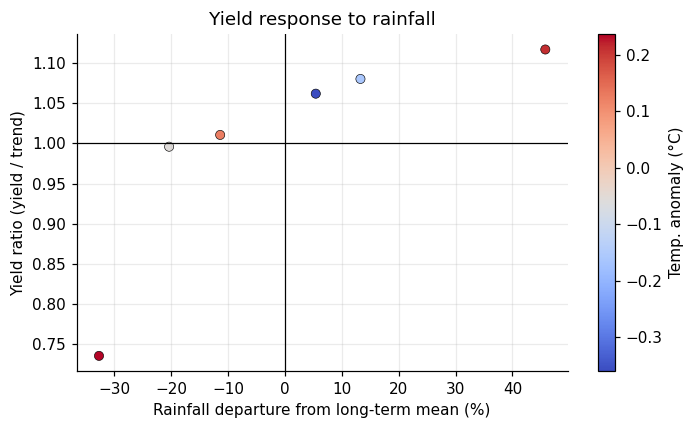

In [8]:
# ---------- Diagnostic: does yield fall when rainfall is below normal? ----------
fig, ax = plt.subplots(figsize=(6.5, 4))
dep = (hist["rain_mm"] / rain_ref - 1) * 100          # rainfall departure from the long-term mean, in %
sc = ax.scatter(dep, hist["yield_ratio"], c=hist["temp_anom_C"], cmap="coolwarm", edgecolor="k", lw=0.4)   # colour = temperature anomaly
ax.axhline(1, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)    # reference lines: normal yield, normal rainfall
ax.set(xlabel="Rainfall departure from long-term mean (%)", ylabel="Yield ratio (yield / trend)",
       title="Yield response to rainfall")
if HAS_TEMP:
    plt.colorbar(sc, label="Temp. anomaly (°C)")
plt.tight_layout(); plt.show()

---
## Step 3: Estimate the yield damage function

**What this step does:** fits a regression that converts climate conditions into **fractional yield loss**. This is the core *sensitivity* relationship: how strongly does yield respond to a rainfall deficit and to warming?

**Model:**  `yield_ratio = b0 + b1·d + b2·d² + b3·T`

- `d` = rainfall deficit, `d²` captures the **nonlinearity** (each extra bit of deficit hurts more than the last)
- `T` = temperature anomaly (°C)
- Coefficients `b1`, `b2`, `b3` are negative, because the deficit and heat reduce yield.

We solve it by ordinary least squares with `numpy`. Then we define `yield_loss(d, T)` = −(b1·d + b2·d² + b3·T), which we use throughout the rest of the notebook.

**What to check:** the R² (how well the model explains the data) and whether the fitted coefficients sit close to the "true" values we used (−0.20, −2.00, −0.03). They should be close, but not exact, because of noise and the short record. Expect the **temperature coefficient to be the hardest to recover**: its true effect is small relative to the noise, so the fit can be off by a large *proportion*. That mismatch is itself a source of uncertainty, and a good reason to test the model's sensitivity to it (an extension idea at the end).

**With real data:** you cannot compare against "true" values, because there is no known truth. Instead judge the fit by (a) the sign of the coefficients (drought should reduce yield), (b) the R², which is often modest (0.2 to 0.6) because pests, prices, inputs and management also drive yields, and (c) the implied loss at a 30% deficit, which the cell prints so you can check it against what agronomists or farmers report. **A note on the intercept `b0`:** it is the yield ratio in a year with no rainfall deficit. With real data it is usually *above* 1.0, because the trend line runs through the average of good and bad years, so a no-drought year sits above trend. The model therefore measures losses *relative to the no-deficit yield* (it divides by `b0`), and the cell prints the implied normal-year yield to help you set `BASE["base_yield"]`. Set `FIT_QUADRATIC = False` if you have only a handful of drought years, since a curved fit can overfit a few points.

**With only a handful of seasons (this version):** the cell below sets `FIT_QUADRATIC = False`, so the model has just three numbers to estimate (intercept, deficit slope, temperature slope) from six observations. A curved (quadratic) fit would use four numbers on six points and would simply memorise them. Even the simpler fit is fragile: drop or add one season and the slope can change noticeably. The next sub-step (**Step 3b**) measures exactly how much.

In [9]:
# =============================================================================
# STEP 3: FIT THE YIELD DAMAGE FUNCTION   yield_ratio = b0 + b1*deficit (+ b2*deficit^2) + b3*temp_anomaly
# =============================================================================
# False = straight-line response (3 numbers to estimate). With only 6 seasons the curved version (4 numbers) would
# just memorise the data, so we use the simpler one. Set True if you have many seasons.
FIT_QUADRATIC = False

# Design matrix X: one column per term of the regression, one row per season
cols = [np.ones(n), deficit] + ([deficit**2] if FIT_QUADRATIC else []) + [temp_anom]
X = np.column_stack(cols)
y = yield_ratio                                       # what we are trying to explain

# Ordinary least squares: find the coefficients that best reproduce the observed yield ratios
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
if FIT_QUADRATIC:
    b0, b1, b2, b3 = coef
else:
    b0, b1, b3 = coef
    b2 = 0.0                                          # no curvature term in the simple version

# R-squared: share of the variation in yields explained by the model (1 = perfect, 0 = nothing)
y_hat = X @ coef
r2 = 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def yield_loss(d, T):
    # Fractional yield loss (0 to 1) for rainfall deficit d and temperature anomaly T.
    # Used by the farm model in Step 4 and by every sensitivity test afterwards.
    d = np.maximum(0, d)                              # only dry conditions reduce yield in this model
    loss = -(b1 * d + b2 * d**2 + b3 * T) / b0        # negative coefficients -> positive loss; divide by b0 to measure
                                                      # losses relative to the no-deficit yield level
    return np.clip(loss, 0, 1)                        # a loss cannot be below 0% or above 100%

print("Fitted coefficients")
if YIELDS_SYNTHETIC:                                  # we know the "true" values only when we invented the yields
    if not FIT_QUADRATIC:
        print("  (The synthetic yields follow a CURVED relationship, so the straight-line fit below cannot match the 'true' "
              "values. Set FIT_QUADRATIC = True to compare like with like.)")
    print(f"  intercept b0 = {b0:6.3f}   (should be near 1.00)")
    print(f"  deficit   b1 = {b1:6.3f}   (true: -0.20)")
    print(f"  deficit^2 b2 = {b2:6.3f}   (true: -2.00)")
    print(f"  temp      b3 = {b3:6.3f}   (true: -0.03)")
else:
    print(f"  intercept b0 = {b0:6.3f}   (yield ratio in a no-deficit year; above 1 is normal, see note)")
    print(f"  deficit   b1 = {b1:6.3f}")
    print(f"  deficit^2 b2 = {b2:6.3f}" + ("" if FIT_QUADRATIC else "   (not fitted)"))
    print(f"  temp      b3 = {b3:6.3f}")
print(f"  R-squared    = {r2:6.3f}")
print(f"  Implied yield loss at a 30% rainfall deficit (no warming): {float(yield_loss(0.3, 0.0)):.1%}")
if not YIELDS_SYNTHETIC:
    print(f"  Implied NORMAL-YEAR (no-deficit) yield at the average of the sample: "
          f"{data['yield_trend'].iloc[-1] * b0:.2f} t/ha  <- consider this for BASE['base_yield']")

# Sanity checks on the fit
if n < 3 * X.shape[1]:                                # rule of thumb: at least ~3 observations per estimated number
    print(f"WARNING: {n} seasons for {X.shape[1]} estimated coefficients is very few. "
          "The coefficients (especially temperature) are unreliable. Step 3b measures how much.")
if b3 > 0:                                            # warmer seasons associated with HIGHER yields is physically implausible here
    print("NOTE: the temperature coefficient has an implausible sign (warmer seasons look BETTER for yield). "
          "In this sample the effects of temperature and rainfall cannot be separated, so treat the "
          "temperature effect as unreliable. The model never turns it into a yield gain (losses are floored at zero).")
if r2 < 0.30:
    print("NOTE: low R-squared. Rainfall explains little of the yield variation in this sample. "
          "Check the season months, location and yield data, and say so in your limitations.")
if float(yield_loss(0.3, 0.0)) <= 0.0:
    print("WARNING: the fit implies NO yield loss from drought. The model will show almost no climate "
          "sensitivity. Revisit the data, try FIT_QUADRATIC = False, or treat results as illustrative only.")

Fitted coefficients
  intercept b0 =  1.102   (yield ratio in a no-deficit year; above 1 is normal, see note)
  deficit   b1 = -0.951
  deficit^2 b2 =  0.000   (not fitted)
  temp      b3 =  0.019
  R-squared    =  0.859
  Implied yield loss at a 30% rainfall deficit (no warming): 25.9%
  Implied NORMAL-YEAR (no-deficit) yield at the average of the sample: 3.01 t/ha  <- consider this for BASE['base_yield']
NOTE: the temperature coefficient has an implausible sign (warmer seasons look BETTER for yield). In this sample the effects of temperature and rainfall cannot be separated, so treat the temperature effect as unreliable. The model never turns it into a yield gain (losses are floored at zero).


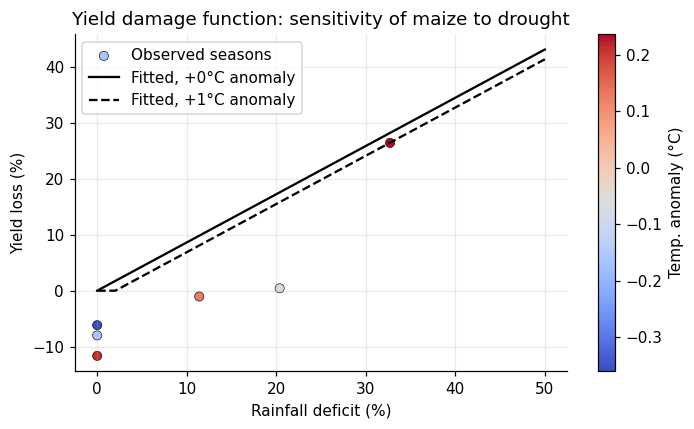

In [10]:
# ---------- Visualise the fitted damage function against the observed seasons ----------
d_grid = np.linspace(0, 0.5, 100)                     # rainfall deficits from 0% to 50%

fig, ax = plt.subplots(figsize=(6.5, 4))
# Dots: the observed seasons (deficit on x, observed yield loss on y), coloured by temperature anomaly
ax.scatter(hist["deficit"] * 100, (1 - hist["yield_ratio"]) * 100,
           c=hist["temp_anom_C"], cmap="coolwarm", edgecolor="k", lw=0.4, label="Observed seasons")
# Lines: the fitted function at no warming (solid) and at +1 degree C warming (dashed)
for T, ls in [(0.0, "-"), (1.0, "--")]:
    ax.plot(d_grid * 100, yield_loss(d_grid, T) * 100, ls=ls, color="k", label=f"Fitted, +{T:.0f}°C anomaly")
ax.set(xlabel="Rainfall deficit (%)", ylabel="Yield loss (%)",
       title="Yield damage function: sensitivity of maize to drought")
ax.legend()
plt.colorbar(ax.collections[0], label="Temp. anomaly (°C)")
plt.tight_layout(); plt.show()


---
## Step 3b: How uncertain is the fitted damage function? (bootstrap)

**What this step does:** with six seasons, the fitted damage function could easily have come out differently if the data had been slightly different. The **bootstrap** measures this directly:

1. Randomly re-draw six seasons *with replacement* from the observed ones (some seasons appear twice, some not at all).
2. Re-fit the damage function on that re-drawn sample and record the **implied yield loss at a 30% rainfall deficit**.
3. Repeat 2,000 times and look at the spread.

**How to read the output**
- The **histogram** shows the plausible range of the damage function. A wide histogram means the data cannot pin down how sensitive maize is to drought. (With only six seasons there are few distinct re-draws, so the histogram looks lumpy. That is normal.)
- The **90% interval** (5th to 95th percentile) is converted into a multiplier on the fitted damage, called `DMG_LO` and `DMG_HI`. For example, 0.6 to 1.4 means "the true damage could be 40% weaker or 40% stronger than the point estimate".
- These multipliers feed straight into the sensitivity analysis: the **tornado chart (Step 7)**, the **Monte Carlo (Step 9)** and the **Sobol analysis (Step 10)** all treat *damage-function strength* as an uncertain input. That way the sensitivity analysis shows how much of your risk comes from not knowing the damage function well.

The multipliers are limited to the range 0.5 to 1.5 so that one extreme resample cannot dominate.


Usable re-fits: 1,964 of 2,000
Implied yield loss at a 30% rainfall deficit:
  original fit: 25.9%
  bootstrap median: 24.9% | 90% interval: 7.6% to 35.4%
Damage-function strength range used in Steps 7, 9 and 10: x0.50 to x1.37


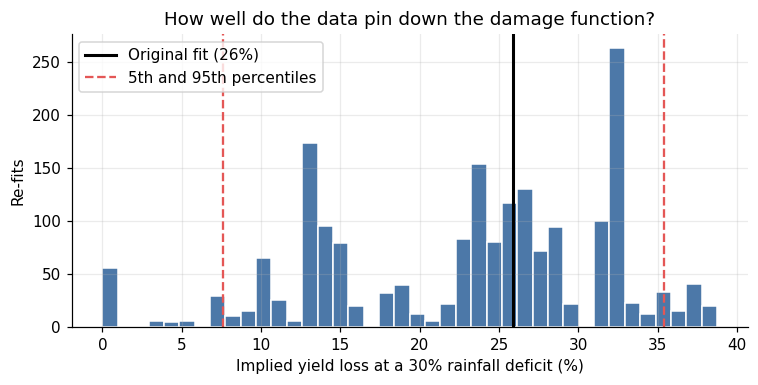

In [11]:

# =============================================================================
# STEP 3b: HOW UNCERTAIN IS THE FITTED DAMAGE FUNCTION?  (bootstrap)
# =============================================================================
N_BOOT = 2000                                         # number of re-fits
rng_boot = np.random.default_rng(SEED)                # its own generator, so this cell never changes later random numbers

boot_loss = []                                        # implied yield loss at a 30% deficit, one value per re-fit
for _ in range(N_BOOT):
    pick = rng_boot.integers(0, n, n)                 # re-draw n seasons WITH replacement (some repeat, some are left out)
    if np.ptp(deficit[pick]) == 0:                    # every drawn season has the same deficit -> no slope to learn; skip
        continue
    cb, *_ = np.linalg.lstsq(X[pick], y[pick], rcond=None)   # re-fit the same regression on the re-drawn seasons
    b0_, b1_ = cb[0], cb[1]
    b2_ = cb[2] if FIT_QUADRATIC else 0.0             # a curvature term exists only in the quadratic version
    if b0_ <= 0:                                      # nonsensical intercept (can happen with tiny samples); skip
        continue
    boot_loss.append(np.clip(-(b1_ * 0.3 + b2_ * 0.3**2) / b0_, 0, 1))   # implied loss at a 30% deficit, no warming
boot_loss = np.array(boot_loss)

point = float(yield_loss(0.3, 0.0))                   # the loss implied by the original fit
lo90, med, hi90 = np.percentile(boot_loss, [5, 50, 95])
print(f"Usable re-fits: {len(boot_loss):,} of {N_BOOT:,}")
print(f"Implied yield loss at a 30% rainfall deficit:")
print(f"  original fit: {point:.1%}")
print(f"  bootstrap median: {med:.1%} | 90% interval: {lo90:.1%} to {hi90:.1%}")

# Turn the interval into multipliers on the fitted damage (1.0 = the original fit).
# Limited to 0.5 - 1.5 so that one extreme re-draw cannot dominate the sensitivity analysis.
DMG_LO = float(np.clip(lo90 / point, 0.5, 1.0)) if point > 0 else 0.7
DMG_HI = float(np.clip(hi90 / point, 1.0, 1.5)) if point > 0 else 1.3
print(f"Damage-function strength range used in Steps 7, 9 and 10: x{DMG_LO:.2f} to x{DMG_HI:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(boot_loss * 100, bins=40, color="#4C78A8", edgecolor="white")
ax.axvline(point * 100, color="k", lw=2, label=f"Original fit ({point:.0%})")
ax.axvline(lo90 * 100, color="#E45756", ls="--", label="5th and 95th percentiles")
ax.axvline(hi90 * 100, color="#E45756", ls="--")
ax.set(xlabel="Implied yield loss at a 30% rainfall deficit (%)", ylabel="Re-fits",
       title="How well do the data pin down the damage function?")
ax.legend()
plt.tight_layout(); plt.show()


---
## Step 4: Build the climate-to-cash-flow model

**What this step does:** wraps the whole chain into one function, `farm_model()`:

**Climate → yield loss → yield → revenue → OCF → DSCR**

Design choices worth noticing:
- **Vectorised:** every input can be a single number *or* an array, so one call can evaluate thousands of scenarios (needed for Monte Carlo and Sobol).
- **Defaults come from `BASE`:** you only pass the inputs you want to change.
- **Fixed costs do not fall when yield falls.** Seeds, fertiliser and overheads are already spent before the drought is known, so revenue drops faster than costs. This is why cash flow is far more sensitive than yield alone.
- **Adaptation hooks:** `sens_mult` scales yield loss (drought-tolerant seed reduces it), `extra_cost_ha` adds cost, and `insurance=True` adds a premium and a rainfall-index payout.

**Rainfall input:** `rain_anom` is the fractional departure from the mean rainfall (−0.20 means 20% below normal; +0.10 means 10% above). The model converts it to a deficit internally.

In [12]:
# =============================================================================
# STEP 4: THE CLIMATE-TO-CASH-FLOW MODEL
#   rainfall deficit -> yield loss -> yield -> revenue -> operating cash flow (OCF) -> DSCR
# =============================================================================
def farm_model(rain_anom=0.0, temp_anom=0.0, price=None, var_cost_ha=None,
               fixed_cost=None, loan=None, base_yield=None, area=None,
               sens_mult=1.0, dmg_scale=1.0, extra_cost_ha=0.0, insurance=False, params=BASE):
    """Climate-to-cash-flow model. Inputs can be single numbers or numpy arrays (so one call can run thousands of scenarios).

    rain_anom : rainfall departure from normal as a fraction (-0.20 = 20% below normal, +0.10 = 10% above)
    temp_anom : temperature anomaly in degrees C
    sens_mult : adaptation lever. Multiplies the yield loss (e.g. 0.6 for drought-tolerant seed)
    dmg_scale : uncertainty lever. Multiplies the fitted damage function (1.0 = as fitted; see Step 3b for its range)
    extra_cost_ha : extra cost per hectare (e.g. the premium for drought-tolerant seed)
    insurance : if True, add the insurance premium and any rainfall-index payout
    Any input left as None is taken from the BASE assumptions in Step 1.
    """
    p = params
    # Use the BASE value for any input the caller did not supply
    price       = p["price"]        if price is None else price
    var_cost_ha = p["var_cost_ha"]  if var_cost_ha is None else var_cost_ha
    fixed_cost  = p["fixed_cost"]   if fixed_cost is None else fixed_cost
    loan        = p["loan"]         if loan is None else loan
    base_yield  = p["base_yield"]   if base_yield is None else base_yield
    area        = p["area_ha"]      if area is None else area

    rain_anom = np.asarray(rain_anom, dtype=float)
    d = np.maximum(0, -rain_anom)                       # rainfall DEFICIT: only the part below normal counts

    # 1) Yield loss from the fitted damage function, scaled by the adaptation and uncertainty levers
    loss = np.clip(sens_mult * dmg_scale * yield_loss(d, temp_anom), 0, 1)
    yld = base_yield * (1 - loss)                        # yield in t/ha after the loss
    revenue = yld * area * price                         # tonnes sold x price
    costs = (var_cost_ha + extra_cost_ha) * area + fixed_cost   # costs barely change when yield falls

    # 2) Optional index insurance: pays out if the rainfall deficit passes a trigger, minus the premium
    insurance_net = 0.0
    if insurance:
        payout = np.where(d > p["ins_trigger2"], p["ins_payout2"],
                  np.where(d > p["ins_trigger1"], p["ins_payout1"], 0.0))
        insurance_net = payout - p["ins_premium"]

    # 3) Operating cash flow and debt service coverage ratio
    ocf = revenue - costs + insurance_net
    return {
        "loss": loss, "yield": yld, "revenue": revenue, "costs": costs,
        "ocf": ocf, "dscr": ocf / loan,                  # DSCR below 1.0 means the loan cannot be repaid from operations
    }

---
## Step 5: Check the baseline

**What this step does:** runs the model with *no climate shock* and confirms it reproduces the numbers we expect by hand. Always validate a model's baseline before running sensitivity analysis, because errors here propagate into every result.

**Expected by hand:**
- Revenue = 3.0 × 500 × 45,000 = KES 67.5M
- Variable costs = 60,000 × 500 = KES 30M; fixed costs = KES 15M
- OCF = 67.5 − 30 − 15 = **KES 22.5M**
- DSCR = 22.5 ÷ 12 = **1.875**

In [13]:
# =============================================================================
# STEP 5: BASELINE CHECK -- run the model with no climate shock and compare with a hand calculation
# =============================================================================
b = farm_model(rain_anom=0.0, temp_anom=0.0)           # normal rainfall, no warming

baseline = pd.Series({
    "Yield (t/ha)": float(b["yield"]),
    "Revenue (KES M)": float(b["revenue"]) / M,
    "Total costs (KES M)": float(b["costs"]) / M,
    "Operating cash flow (KES M)": float(b["ocf"]) / M,
    "DSCR": float(b["dscr"]),
})
display(baseline.to_frame("Baseline"))

# By hand: revenue 3.0 x 500 x 45,000 = 67.5M; costs 60,000 x 500 + 15M = 45M; OCF = 22.5M
assert abs(float(b["ocf"]) / M - 22.5) < 1e-6, "Baseline OCF does not match hand calculation"
print("Baseline check passed.")

,Baseline
Yield (t/ha),3.00
Revenue (KES M),67.50
Total costs (KES M),45.00
Operating cash flow (KES M),22.50
DSCR,1.88


Baseline check passed.


---
## Step 6: Scenario sensitivity and the breaking point

**What this step does:** raises the rainfall deficit in steps from 0% to 40% (holding temperature at a +0.5 °C anomaly) and records yield, OCF and DSCR. This is the simplest and most communicable form of sensitivity analysis.

Then it finds the **breaking point**: the rainfall deficit at which DSCR falls to 1.0 (the farm can no longer service its loan). This is where sensitivity analysis meets **stress testing**.

Finally it asks: *how does that breaking point move if the maize price changes?* This is a **threshold sensitivity**: not "how much does the output change?" but "how much does the failure point shift?"

**Method note:** the breaking point is found with `scipy.optimize.brentq`, a root finder that searches for the deficit where `DSCR − 1 = 0`. If the farm already fails with no drought at all (as happens at very low prices), the function returns 0%, meaning there is no climate buffer left.

In [14]:
# =============================================================================
# STEP 6a: SCENARIO SENSITIVITY -- raise the rainfall deficit step by step
# =============================================================================
T_REF = 0.5                                            # temperature anomaly held constant in the scenario table (deg C)

deficits = np.arange(0, 0.41, 0.05)                    # 0%, 5%, ... 40% rainfall deficit
res = farm_model(rain_anom=-deficits, temp_anom=T_REF) # one call evaluates all nine deficits at once

scen = pd.DataFrame({
    "Rainfall deficit (%)": deficits * 100,
    "Yield loss (%)": res["loss"] * 100,
    "Yield (t/ha)": res["yield"],
    "Revenue (KES M)": res["revenue"] / M,
    "OCF (KES M)": res["ocf"] / M,
    "DSCR": res["dscr"],
})
scen["Can repay loan?"] = np.where(scen["DSCR"] >= 1, "Yes", "NO")
display(scen.round(2))

,Rainfall deficit (%),Yield loss (%),Yield (t/ha),Revenue (KES M),OCF (KES M),DSCR,Can repay loan?
0,0.00,0.00,3.00,67.50,22.50,1.88,Yes
1,5.00,3.44,2.90,65.18,20.18,1.68,Yes
2,10.00,7.75,2.77,62.27,17.27,1.44,Yes
3,15.00,12.06,2.64,59.36,14.36,1.20,Yes
4,20.00,16.38,2.51,56.45,11.45,0.95,NO
5,25.00,20.69,2.38,53.54,8.54,0.71,NO
6,30.00,25.00,2.25,50.62,5.62,0.47,NO
7,35.00,29.31,2.12,47.71,2.71,0.23,NO
8,40.00,33.63,1.99,44.80,-0.20,-0.02,NO


In [15]:
# =============================================================================
# STEP 6b: THE BREAKING POINT -- the rainfall deficit at which the loan can no longer be repaid
# =============================================================================
def breaking_point(target=1.0, **kw):
    """Rainfall deficit (as a fraction) at which DSCR falls to `target`.
    Returns 0.0 if the farm already fails with no drought (e.g. at a very low price).
    Returns NaN if DSCR never falls to `target`, even with an 80% deficit (the fitted damage is too weak).
    Extra keyword arguments (price=..., dmg_scale=...) are passed to farm_model."""
    gap = lambda a: float(farm_model(rain_anom=a, temp_anom=T_REF, **kw)["dscr"]) - target   # zero at the breaking point
    if gap(0.0) < 0:                                   # already below the target with normal rainfall
        return 0.0
    if gap(-0.8) > 0:                                  # still above the target at an 80% deficit: no breaking point exists
        return np.nan
    return -brentq(gap, -0.8, 0.0)                     # search between a 0% and an 80% deficit

def fmt_bp(x):
    # Text for a breaking point, including the "does not exist" case
    return "never, even at an 80% rainfall deficit" if np.isnan(x) else f"at a rainfall deficit of about {x:.1%}"

bp_dscr1 = breaking_point(target=1.0)                  # DSCR = 1: the loan can no longer be serviced
bp_ocf0  = breaking_point(target=0.0)                  # DSCR = 0: operating cash flow turns negative
print(f"Loan repayment fails (DSCR < 1): {fmt_bp(bp_dscr1)}")
print(f"Operating cash flow turns negative: {fmt_bp(bp_ocf0)}")

Loan repayment fails (DSCR < 1): at a rainfall deficit of about 19.0%
Operating cash flow turns negative: at a rainfall deficit of about 39.7%


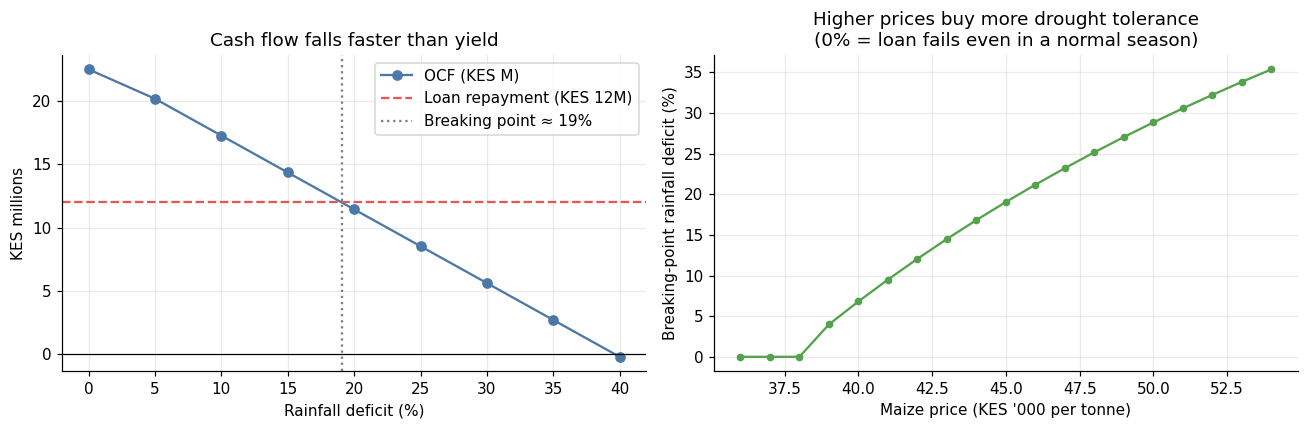

In [16]:
# ---------- Charts for Step 6 ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: operating cash flow against rainfall deficit, with the loan repayment as a hurdle
ax = axes[0]
ax.plot(deficits * 100, res["ocf"] / M, color="#4C78A8", marker="o", label="OCF (KES M)")
ax.axhline(BASE["loan"] / M, color="#E45756", ls="--", label="Loan repayment (KES 12M)")
ax.axhline(0, color="k", lw=0.8)
if not np.isnan(bp_dscr1):                         # draw the breaking point only if one exists
    ax.axvline(bp_dscr1 * 100, color="grey", ls=":", label=f"Breaking point ≈ {bp_dscr1:.0%}")
ax.set(xlabel="Rainfall deficit (%)", ylabel="KES millions", title="Cash flow falls faster than yield")
ax.legend()

# Right: threshold sensitivity -- how does the breaking point move when the maize price changes?
prices = np.linspace(36_000, 54_000, 19)
bps = [breaking_point(price=pr) * 100 for pr in prices]
ax = axes[1]
ax.plot(prices / 1000, bps, color="#54A24B", marker="o", ms=4)
ax.set(xlabel="Maize price (KES '000 per tonne)", ylabel="Breaking-point rainfall deficit (%)",
       title="Higher prices buy more drought tolerance\n(0% = loan fails even in a normal season)")
plt.tight_layout(); plt.show()

---
## Step 7: One-at-a-time (local) sensitivity and the tornado chart

**What this step does:** starts from a **reference scenario**, a moderate drought (15% rainfall deficit, +0.5 °C), and moves **one input at a time** across a plausible low–high range while holding the others at reference. We record the DSCR at each end.

The **tornado chart** ranks inputs by the size of their swing in DSCR. The longest bars are the inputs your result is most sensitive to.

**Inputs and plausible ranges (illustrative)**

| Input | Low | High |
|---|---|---|
| Rainfall departure | −5% | −25% |
| Temperature anomaly | 0.0 °C | +1.0 °C |
| Maize price | KES 36,000 | KES 54,000 |
| Variable cost per ha | KES 51,000 | KES 69,000 |
| Fixed cost | KES 13.5M | KES 16.5M |
| Baseline yield | 2.55 t/ha | 3.45 t/ha |
| Loan repayment | KES 10.8M | KES 13.2M |
| Damage-function strength (× multiplier) | `DMG_LO` from Step 3b | `DMG_HI` from Step 3b |

**Caution:** the ranges are *not* equally likely. A ±20% price move is not equivalent to a ±20% rainfall move. A tornado chart ranks sensitivity **given the ranges you chose**, so justify them. Step 10 removes some of this arbitrariness.

In [17]:
# =============================================================================
# STEP 7a: ONE-AT-A-TIME SENSITIVITY -- move each input across its range, holding the others at the reference
# =============================================================================
REF = dict(rain_anom=-0.15, temp_anom=0.5)             # reference scenario: a moderate drought (15% deficit, +0.5 deg C)
ref_dscr = float(farm_model(**REF)["dscr"])
print(f"Reference scenario DSCR = {ref_dscr:.2f}")

# label: (farm_model argument, low value, high value). The ranges should bracket the reference value.
oat_ranges = {
    "Rainfall departure":        ("rain_anom",   -0.05,  -0.25),
    "Temperature anomaly (°C)":  ("temp_anom",   0.0,    1.0),
    "Maize price":               ("price",       36_000, 54_000),
    "Variable cost per ha":      ("var_cost_ha", 51_000, 69_000),
    "Fixed cost":                ("fixed_cost",  13.5e6, 16.5e6),
    "Baseline yield":            ("base_yield",  2.55,   3.45),
    "Loan repayment":            ("loan",        10.8e6, 13.2e6),
    # Uncertainty in the damage function itself, taken from the Step 3b bootstrap
    "Damage-function strength (x)": ("dmg_scale", DMG_LO, DMG_HI),
}

rows = []
for label, (name, lo, hi) in oat_ranges.items():
    out = []
    for val in (lo, hi):                               # evaluate the model at the low and the high end of the range
        kw = dict(REF); kw[name] = val                 # start from the reference, change ONE input
        out.append(float(farm_model(**kw)["dscr"]))
    rows.append({"Input": label, "DSCR @ low": out[0], "DSCR @ high": out[1],
                 "Swing": abs(out[1] - out[0])})       # swing = how far DSCR moves across the range

tornado = pd.DataFrame(rows).sort_values("Swing", ascending=True).reset_index(drop=True)
display(tornado.sort_values("Swing", ascending=False).reset_index(drop=True))

Reference scenario DSCR = 1.20


,Input,DSCR @ low,DSCR @ high,Swing
0,Maize price,0.21,2.19,1.98
1,Baseline yield,0.45,1.94,1.48
2,Rainfall departure,1.68,0.71,0.97
3,Variable cost per ha,1.57,0.82,0.75
4,Damage-function strength (x),1.54,0.95,0.59
5,Fixed cost,1.32,1.07,0.25
6,Loan repayment,1.33,1.09,0.24
7,Temperature anomaly (°C),1.15,1.25,0.10


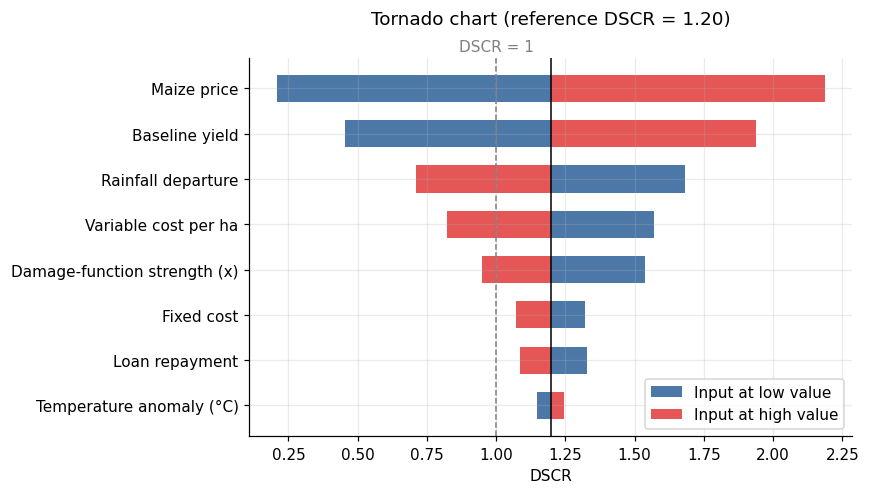

In [18]:
# ---------- Tornado chart: the longest bars are the inputs the result is most sensitive to ----------
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, r in tornado.iterrows():
    # one bar from the reference DSCR to the DSCR at the LOW input value, another to the HIGH input value
    ax.barh(i, r["DSCR @ low"] - ref_dscr,  left=ref_dscr, color="#4C78A8", height=0.6,
            label="Input at low value" if i == 0 else None)
    ax.barh(i, r["DSCR @ high"] - ref_dscr, left=ref_dscr, color="#E45756", height=0.6,
            label="Input at high value" if i == 0 else None)
ax.axvline(ref_dscr, color="k", lw=1)                  # reference scenario
ax.axvline(1.0, color="grey", ls="--", lw=1)           # DSCR = 1: the loan cannot be repaid to the left of this line
ax.text(1.0, 1.01, "DSCR = 1", color="grey", ha="center", va="bottom", transform=ax.get_xaxis_transform())
ax.set_yticks(range(len(tornado))); ax.set_yticklabels(tornado["Input"])
ax.set_xlabel("DSCR")
ax.set_title(f"Tornado chart (reference DSCR = {ref_dscr:.2f})", pad=22)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

---
## Step 8: Two-way sensitivity (heatmap)

**What this step does:** varies **two inputs together**, rainfall deficit and maize price, and maps the resulting DSCR. One-at-a-time analysis cannot show interactions; a two-way grid can.

**How to read it:** the bold contour line is **DSCR = 1**. Combinations to the left of or above that line (small deficit and high price) are safe; combinations to the right and below it cannot service the loan. Notice how the line slopes: a higher price allows a bigger deficit before failure.

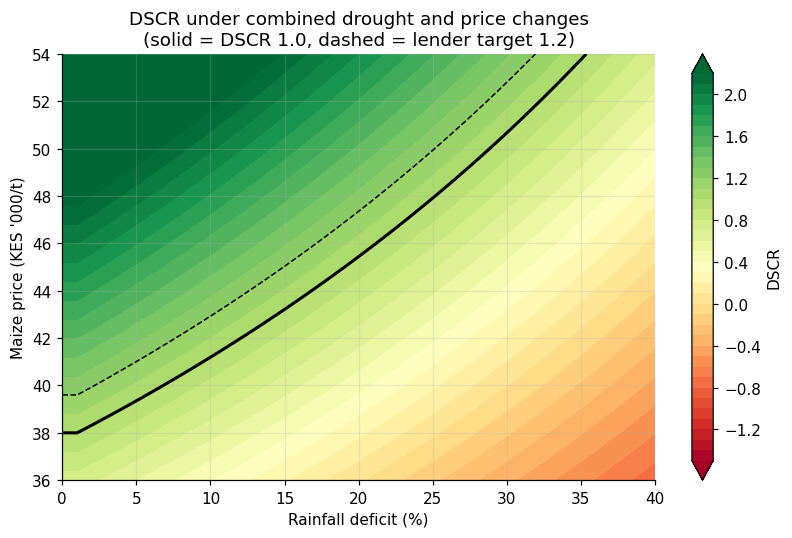

In [19]:
# =============================================================================
# STEP 8: TWO-WAY SENSITIVITY -- vary rainfall deficit AND price together
# =============================================================================
defs = np.linspace(0, 0.40, 81)                        # 81 rainfall deficits from 0% to 40%
prices = np.linspace(36_000, 54_000, 81)               # 81 prices
DD, PP = np.meshgrid(defs, prices)                     # every combination of the two (a 81 x 81 grid)
dscr_grid = farm_model(rain_anom=-DD, temp_anom=T_REF, price=PP)["dscr"]   # DSCR for all 6,561 combinations at once

fig, ax = plt.subplots(figsize=(7.5, 5))
cs = ax.contourf(DD * 100, PP / 1000, dscr_grid, levels=np.linspace(-1.5, 2.2, 38), cmap="RdYlGn", extend="both")
ax.contour(DD * 100, PP / 1000, dscr_grid, levels=[1.0], colors="k", linewidths=2)                       # DSCR = 1 (fails)
ax.contour(DD * 100, PP / 1000, dscr_grid, levels=[1.2], colors="k", linewidths=1, linestyles="--")      # DSCR = 1.2 (lender target)
plt.colorbar(cs, label="DSCR")
ax.set(xlabel="Rainfall deficit (%)", ylabel="Maize price (KES '000/t)",
       title="DSCR under combined drought and price changes\n(solid = DSCR 1.0, dashed = lender target 1.2)")
plt.tight_layout(); plt.show()

---
## Step 9: Monte Carlo simulation (probabilistic risk)

**What this step does:** instead of picking scenarios by hand, we draw **20,000 random combinations** of the uncertain inputs from realistic distributions and run the model on each. The result is a *distribution* of outcomes, from which we read probabilities.

**Distributions used**
- **Rainfall:** a gamma distribution *fitted to the historical rainfall* from Step 2, so the simulation reflects the data's own variability.
- **Temperature anomaly:** Normal(+0.5 °C, 0.4), representing a modestly warmer current climate.
- **Maize price:** lognormal around KES 45,000 with about 12% volatility.
- **Variable cost per ha:** Normal(60,000, 4,000).
- **Baseline yield:** Normal(3.0, 0.2) t/ha, for farm-level management variation.
- **Damage-function strength:** Normal(1.0, sd), where the standard deviation comes from the Step 3b bootstrap interval. This carries the uncertainty about the fitted damage function into the simulation.

**Outputs:** mean and 5th-percentile OCF, probability OCF is negative, and the **probability DSCR < 1**, which is a direct, decision-relevant risk measure. We also report the same measures **for drought years only** (rainfall more than 20% below normal), because that is the climate risk the adaptation options in Step 11 are designed to address.

We store the random draws in `mc_inputs` so Steps 10 and 11 can reuse them (using the same draws when comparing options is called *common random numbers* and makes comparisons fairer).

In [20]:
# =============================================================================
# STEP 9: MONTE CARLO -- draw many random combinations of the uncertain inputs and read off probabilities
# =============================================================================
N = 20_000                                             # number of simulated seasons

# Fit a gamma distribution to the observed seasonal rainfall (floc=0: rainfall cannot be negative)
g_shape, g_loc, g_scale = stats.gamma.fit(rain_full.values, floc=0)   # full climate record, not just the yield years
print(f"Fitted rainfall gamma: shape={g_shape:.1f}, scale={g_scale:.1f} (mean {g_shape*g_scale:.0f} mm, "
      f"CV {1/np.sqrt(g_shape):.0%}, from {len(rain_full)} seasons)")
if len(rain_full) < 15:
    print("WARNING: this distribution is based on very few seasons, so the simulated rainfall variability is uncertain.")

# Spread of the damage-function strength, taken from the Step 3b bootstrap:
# a 90% interval spans about 3.29 standard deviations of a normal distribution.
dmg_sd = (DMG_HI - DMG_LO) / 3.29

mc_rain = stats.gamma.rvs(g_shape, loc=0, scale=g_scale, size=N, random_state=rng)   # simulated seasonal rainfall (mm)
mc_inputs = {
    "rain_anom":   mc_rain / rain_ref - 1,                              # rainfall as a departure from normal
    "temp_anom":   rng.normal(0.5, 0.4, N),                             # a modestly warmer climate, with spread
    "price":       BASE["price"] * np.exp(rng.normal(0, 0.12, N)),      # lognormal price, about 12% volatility
    "var_cost_ha": rng.normal(BASE["var_cost_ha"], 4_000, N),           # variable cost per ha
    "base_yield":  np.clip(rng.normal(BASE["base_yield"], 0.2, N), 2.0, None),   # farm-level management variation
    "dmg_scale":   np.clip(rng.normal(1.0, dmg_sd, N), 0.3, None),      # uncertainty in the damage function
}

mc = farm_model(**mc_inputs)                           # run the farm model on all 20,000 simulated seasons at once

def summarise(out, rain_anom=None):
    """Summary risk metrics. If rainfall is supplied, also report metrics for drought years
    (rainfall more than 20% below normal), which is where adaptation is meant to help."""
    ocf, dscr = out["ocf"], out["dscr"]
    res = {
        "Mean OCF (KES M)": ocf.mean() / M,
        "5th pct OCF (KES M)": np.percentile(ocf, 5) / M,              # a "bad year" outcome
        "P(OCF < 0)": (ocf < 0).mean(),                                # chance operating cash flow is negative
        "P(DSCR < 1.0)": (dscr < 1.0).mean(),                          # chance the loan cannot be repaid
        "P(DSCR < 1.2)": (dscr < 1.2).mean(),                          # chance of missing a typical lender target
    }
    if rain_anom is not None:
        drought = np.asarray(rain_anom) < -0.20                        # a drought year = rainfall >20% below normal
        res["P(drought year)"] = drought.mean()
        res["Mean OCF in drought years (KES M)"] = ocf[drought].mean() / M
        res["P(DSCR < 1.0 | drought year)"] = (dscr[drought] < 1.0).mean()
    return res

mc_summary = pd.Series(summarise(mc, mc_inputs["rain_anom"])).to_frame("No adaptation")
display(mc_summary)

Fitted rainfall gamma: shape=15.9, scale=28.0 (mean 446 mm, CV 25%, from 6 seasons)


,No adaptation
Mean OCF (KES M),17.43
5th pct OCF (KES M),-2.69
P(OCF < 0),0.08
P(DSCR < 1.0),0.31
P(DSCR < 1.2),0.39
P(drought year),0.22
Mean OCF in drought years (KES M),5.05
P(DSCR < 1.0 | drought year),0.76


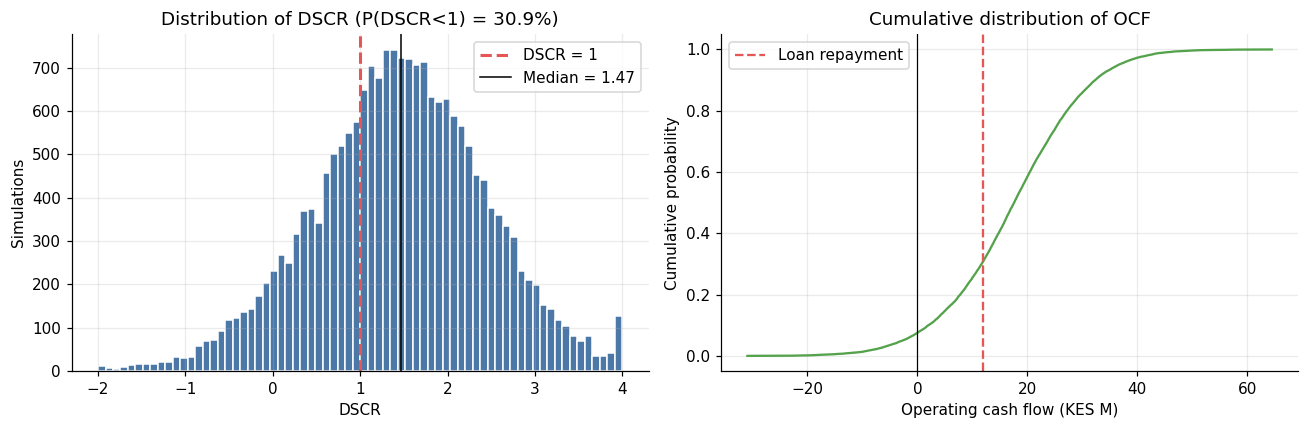

In [21]:
# ---------- Monte Carlo charts ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: distribution of DSCR across the simulations (everything left of the red line cannot repay the loan)
ax = axes[0]
ax.hist(np.clip(mc["dscr"], -2, 4), bins=70, color="#4C78A8", edgecolor="white")    # clipped so extreme values do not stretch the axis
ax.axvline(1.0, color="#E45756", ls="--", lw=2, label="DSCR = 1")
ax.axvline(np.median(mc["dscr"]), color="k", lw=1, label=f"Median = {np.median(mc['dscr']):.2f}")
ax.set(xlabel="DSCR", ylabel="Simulations", title=f"Distribution of DSCR (P(DSCR<1) = {(mc['dscr']<1).mean():.1%})")
ax.legend()

# Right: cumulative distribution of operating cash flow (read off "what share of seasons is below X?")
ax = axes[1]
srt = np.sort(mc["ocf"] / M)
ax.plot(srt, np.linspace(0, 1, N), color="#54A24B")
ax.axvline(0, color="k", lw=0.8)
ax.axvline(BASE["loan"] / M, color="#E45756", ls="--", label="Loan repayment")
ax.set(xlabel="Operating cash flow (KES M)", ylabel="Cumulative probability",
       title="Cumulative distribution of OCF"); ax.legend()
plt.tight_layout(); plt.show()

---
## Step 10: Global sensitivity analysis

One-at-a-time analysis changes a single input while the rest stay fixed. **Global methods** vary *all* inputs at once across their whole ranges, so they capture interactions and give a more honest ranking. We use two approaches.

### 10a. Rank correlation on the Monte Carlo sample (quick and cheap)
Spearman's ρ between each input and DSCR. The sign shows the direction (a negative value means higher input, lower DSCR) and the size shows strength. It only captures monotonic effects, but needs no extra model runs.

### 10b. Sobol variance-based indices (rigorous)
Sobol analysis splits the *variance* of the output into shares attributable to each input.
- **S1 (first-order index):** share of output variance caused by that input **alone**.
- **ST (total-order index):** share caused by that input **including all its interactions** with others.
- **ST − S1** measures how much the input matters through **interactions**. This model is multiplicative (yield × area × price), so interactions are expected.

The Sobol analysis uses uniform ranges for each input (so it ranks *importance*, not probabilities) and `SALib`'s Saltelli sampling.

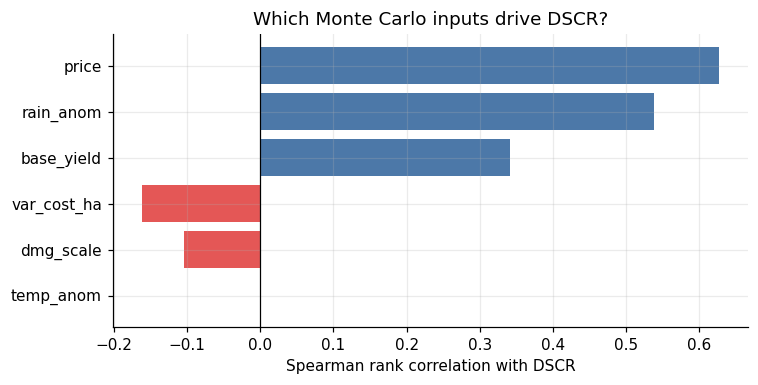

,Spearman rho
price,0.63
rain_anom,0.54
base_yield,0.34
var_cost_ha,-0.16
dmg_scale,-0.10
temp_anom,0.00


In [22]:
# =============================================================================
# STEP 10a: RANK CORRELATION -- a quick global sensitivity check on the Monte Carlo sample
# =============================================================================
mc_df = pd.DataFrame(mc_inputs)                        # the random inputs, one column per input
# Spearman rho between each input and the DSCR: sign = direction, size = strength of the (monotonic) link
rho = {c: stats.spearmanr(mc_df[c], mc["dscr"])[0] for c in mc_df.columns}
rho = pd.Series(rho).sort_values(key=np.abs, ascending=True)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(rho.index, rho.values, color=np.where(rho.values < 0, "#E45756", "#4C78A8"))   # red = higher input lowers DSCR
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Spearman rank correlation with DSCR", title="Which Monte Carlo inputs drive DSCR?")
plt.tight_layout(); plt.show()

display(rho.sort_values(key=np.abs, ascending=False).to_frame("Spearman rho"))

In [23]:
# =============================================================================
# STEP 10b: SOBOL VARIANCE-BASED SENSITIVITY -- how much of the DSCR variance does each input explain?
# =============================================================================
# Each input varies uniformly between its bounds. These ranks show IMPORTANCE, not probability.
problem = {
    "num_vars": 7,
    "names": ["rain_anom", "temp_anom", "price", "var_cost_ha", "base_yield", "fixed_cost", "dmg_scale"],
    "bounds": [
        [-0.40, 0.30],          # rainfall departure: from a 40% deficit to a 30% surplus
        [0.0, 1.5],             # temperature anomaly (deg C)
        [36_000, 54_000],       # price (KES per tonne)
        [51_000, 69_000],       # variable cost per ha
        [2.5, 3.5],             # baseline yield (t/ha)
        [13.5e6, 16.5e6],       # fixed cost (KES)
        [DMG_LO, DMG_HI],       # damage-function strength (from the Step 3b bootstrap)
    ],
}

# Saltelli sampling: N=1024 with 7 inputs and no second-order terms gives 1024 x (7 + 2) = 9,216 model runs
param_values = sobol_sample.sample(problem, 1024, calc_second_order=False, seed=SEED)
inp = dict(zip(problem["names"], param_values.T))      # one array of sampled values per input
Y = farm_model(**inp)["dscr"]                          # run the farm model on every sample

# Turn the model output into sensitivity indices
Si = sobol_analyze.analyze(problem, Y, calc_second_order=False, print_to_console=False, seed=SEED)

sobol_df = pd.DataFrame({
    "S1 (alone)": Si["S1"], "S1 conf": Si["S1_conf"],                 # first-order: effect of the input on its own
    "ST (incl. interactions)": Si["ST"], "ST conf": Si["ST_conf"],    # total-order: including interactions with other inputs
}, index=problem["names"])
sobol_df["Interaction (ST-S1)"] = sobol_df["ST (incl. interactions)"] - sobol_df["S1 (alone)"]   # part due to interactions
sobol_df = sobol_df.sort_values("ST (incl. interactions)", ascending=False)
display(sobol_df.round(3))
print(f"Model runs: {len(Y):,}")

,S1 (alone),S1 conf,ST (incl. interactions),ST conf,Interaction (ST-S1)
price,0.34,0.05,0.35,0.03,0.01
rain_anom,0.32,0.04,0.35,0.04,0.03
base_yield,0.24,0.04,0.24,0.02,0.00
var_cost_ha,0.04,0.02,0.04,0.00,0.00
dmg_scale,0.01,0.02,0.04,0.01,0.03
fixed_cost,0.01,0.01,0.01,0.00,-0.00
temp_anom,0.00,0.00,0.00,0.00,0.00


Model runs: 9,216


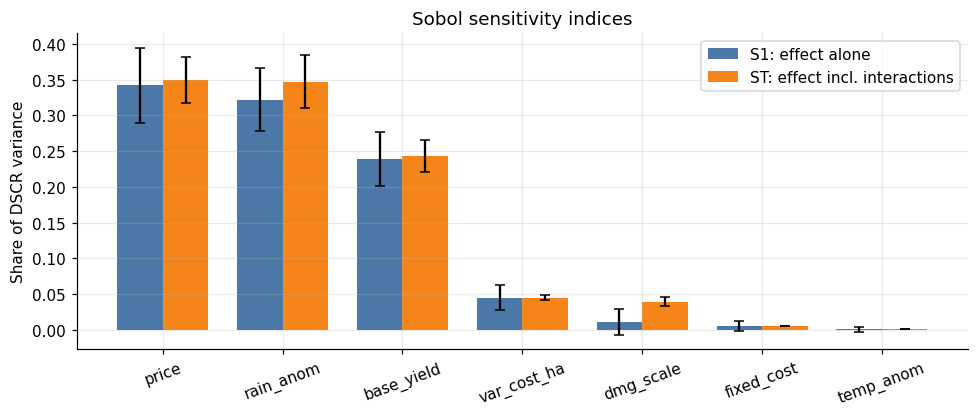

In [24]:
# ---------- Sobol chart: S1 (effect alone) next to ST (effect including interactions) ----------
fig, ax = plt.subplots(figsize=(9, 3.9))
idx = np.arange(len(sobol_df)); w = 0.38
ax.bar(idx - w/2, sobol_df["S1 (alone)"], w, yerr=sobol_df["S1 conf"], color="#4C78A8",
       label="S1: effect alone", capsize=3)               # error bars = 95% confidence interval from the sampling
ax.bar(idx + w/2, sobol_df["ST (incl. interactions)"], w, yerr=sobol_df["ST conf"], color="#F58518",
       label="ST: effect incl. interactions", capsize=3)
ax.set_xticks(idx); ax.set_xticklabels(sobol_df.index, rotation=20)
ax.set(ylabel="Share of DSCR variance", title="Sobol sensitivity indices")
ax.legend()
plt.tight_layout(); plt.show()

---
## Step 11: Stress test and adaptation options

**What this step does:** now that we know *what drives risk*, we test what we can *do* about it.

**Stress scenario (severe but plausible):** 35% rainfall deficit, +1.0 °C, and variable costs up 10% (inputs get dearer in a drought year), with no price relief.

**Options compared**
1. **No adaptation** (baseline)
2. **Drought-tolerant seed:** reduces yield loss by 40% (`sens_mult = 0.6`), costs KES 3,000 more per ha
3. **Rainfall-index insurance:** KES 2M premium, pays KES 6M if the deficit exceeds 20% and KES 12M if it exceeds 30%
4. **Both combined**

We evaluate each option two ways:
- **Deterministic stress test:** DSCR in the stress scenario, pass or fail.
- **Probabilistic comparison:** Monte Carlo (same random draws for fairness), looking at mean OCF, the bad-year tail, and the probability the loan is not covered, both **across all years** and **in drought years only**.

**What to expect, and why it matters:** failures in the Monte Carlo come from *both* climate and non-climate causes (price, yield variation). Adaptation only fixes the climate part. So the all-years probability may barely move, while the drought-year numbers improve noticeably. Reading both avoids the wrong conclusion that adaptation "does nothing".

This links to Module 15: adaptation has a cost, so the question is not "does it help?" but "is the reduction in risk worth what it costs?"

In [25]:
# =============================================================================
# STEP 11a: STRESS TEST AND ADAPTATION OPTIONS -- a severe-but-plausible season, with and without adaptation
# =============================================================================
# Each option is a set of farm_model arguments (an empty dict = no adaptation)
options = {
    "No adaptation":          dict(),
    "Drought-tolerant seed":  dict(sens_mult=0.6, extra_cost_ha=3_000),    # 40% less drought loss, KES 3,000/ha extra
    "Index insurance":        dict(insurance=True),                        # premium plus rainfall-index payout
    "Seed + insurance":       dict(sens_mult=0.6, extra_cost_ha=3_000, insurance=True),
}

# ---- Deterministic stress test: one specific severe scenario ----
stress = dict(rain_anom=-0.35, temp_anom=1.0, var_cost_ha=BASE["var_cost_ha"] * 1.10)   # 35% deficit, +1 deg C, costs +10%

stress_rows = []
for name, kw in options.items():
    o = farm_model(**stress, **kw)                     # same shock, different adaptation
    stress_rows.append({"Option": name, "Yield (t/ha)": float(o["yield"]),
                        "OCF (KES M)": float(o["ocf"]) / M, "DSCR": float(o["dscr"]),
                        "Loan covered?": "Yes" if float(o["dscr"]) >= 1 else "NO"})
stress_df = pd.DataFrame(stress_rows).set_index("Option")
print("STRESS SCENARIO: 35% rainfall deficit, +1.0 °C, variable costs +10%")
display(stress_df.round(2))

STRESS SCENARIO: 35% rainfall deficit, +1.0 °C, variable costs +10%


,Yield (t/ha),OCF (KES M),DSCR,Loan covered?
Option,,,,
No adaptation,2.15,0.30,0.03,NO
Drought-tolerant seed,2.49,6.48,0.54,NO
Index insurance,2.15,10.30,0.86,NO
Seed + insurance,2.49,16.48,1.37,Yes


,No adaptation,Drought-tolerant seed,Index insurance,Seed + insurance
Mean OCF (KES M),17.43,18.14,17.39,18.10
5th pct OCF (KES M),-2.69,1.93,1.58,3.51
P(OCF < 0),0.07,0.03,0.03,0.02
P(DSCR < 1.0),0.31,0.28,0.31,0.27
P(DSCR < 1.2),0.39,0.37,0.40,0.37
P(drought year),0.22,0.22,0.22,0.22
Mean OCF in drought years (KES M),5.05,10.71,11.98,17.64
P(DSCR < 1.0 | drought year),0.76,0.57,0.51,0.28


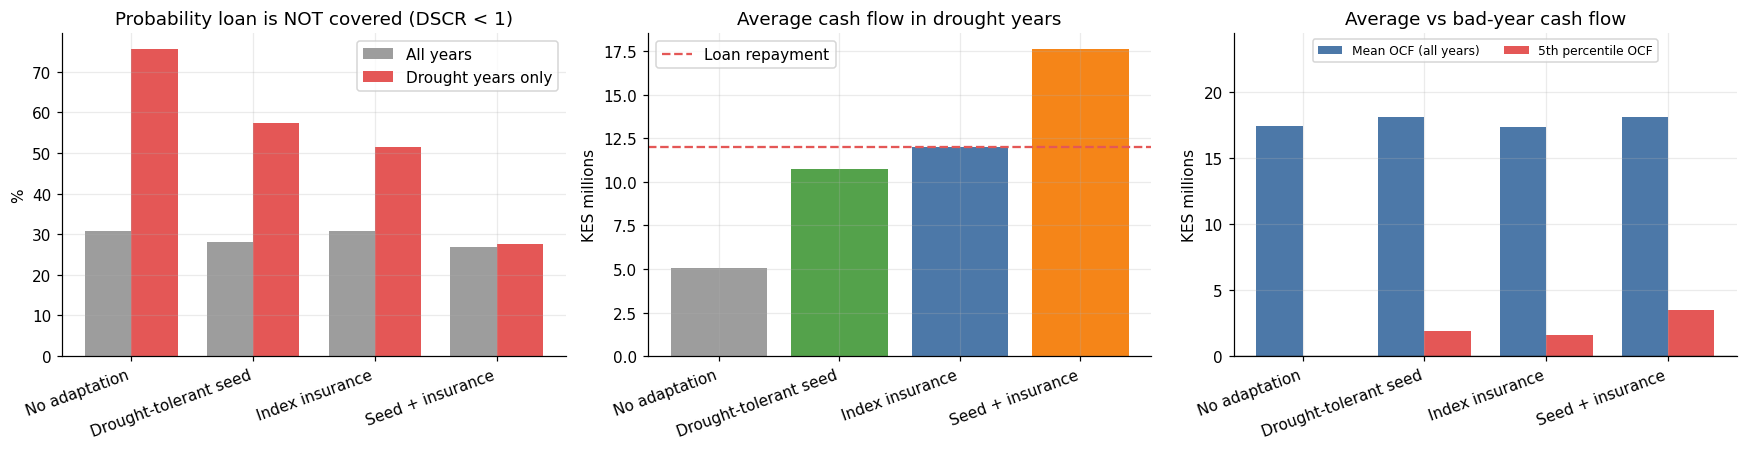

In [26]:
# =============================================================================
# STEP 11b: PROBABILISTIC COMPARISON OF ADAPTATION OPTIONS (same random draws for every option = fair comparison)
# =============================================================================
comp = {}
for name, kw in options.items():
    comp[name] = summarise(farm_model(**mc_inputs, **kw), mc_inputs["rain_anom"])   # reuse the Step 9 simulations
comp_df = pd.DataFrame(comp)
display(comp_df.round(3))

# ---- Charts ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
names = list(options.keys())
x = np.arange(len(names)); w = 0.38

# Panel 1: probability the loan is not covered, all years vs drought years only
axes[0].bar(x - w/2, comp_df.loc["P(DSCR < 1.0)"] * 100, w, color="#9D9D9D", label="All years")
axes[0].bar(x + w/2, comp_df.loc["P(DSCR < 1.0 | drought year)"] * 100, w, color="#E45756", label="Drought years only")
axes[0].set(ylabel="%", title="Probability loan is NOT covered (DSCR < 1)"); axes[0].legend()

# Panel 2: average cash flow in drought years against the loan repayment
axes[1].bar(names, comp_df.loc["Mean OCF in drought years (KES M)"], color=["#9D9D9D", "#54A24B", "#4C78A8", "#F58518"])
axes[1].axhline(BASE["loan"] / M, color="#E45756", ls="--", label="Loan repayment")
axes[1].set(ylabel="KES millions", title="Average cash flow in drought years"); axes[1].legend()

# Panel 3: the price of adaptation: average vs bad-year cash flow
axes[2].bar(x - w/2, comp_df.loc["Mean OCF (KES M)"], w, color="#4C78A8", label="Mean OCF (all years)")
axes[2].bar(x + w/2, comp_df.loc["5th pct OCF (KES M)"], w, color="#E45756", label="5th percentile OCF")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylim(0, comp_df.loc["Mean OCF (KES M)"].max() * 1.35)             # headroom for the legend
axes[2].legend(loc="upper center", ncol=2, fontsize=8)
axes[2].set(ylabel="KES millions", title="Average vs bad-year cash flow")

for a in axes:
    a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=20, ha="right")
plt.tight_layout(); plt.show()

---
## Step 12: Findings, limitations and extensions

The next cell assembles the main results automatically from the analysis above, so the numbers in your write-up always match the code. Then read the limitations and extension ideas below.

In [27]:
# =============================================================================
# STEP 12: KEY FINDINGS -- assembled automatically from the results above so the numbers always match the code
# =============================================================================
top_oat   = tornado.sort_values("Swing", ascending=False).iloc[0]       # input with the largest one-at-a-time swing
top_sobol = sobol_df.index[0]                                           # input with the largest total Sobol index
drought_col = "P(DSCR < 1.0 | drought year)"
best_prob = comp_df.loc[drought_col].idxmin()                           # adaptation option that lowers drought-year failure the most
cost_of_best = comp_df.loc["Mean OCF (KES M)", "No adaptation"] - comp_df.loc["Mean OCF (KES M)", best_prob]

print(f"KEY FINDINGS (illustrative data; damage function fitted on {n} seasons" + (" - a very short record)" if n < 15 else ")"))
print("-" * 70)
print(f"1. Baseline: OCF KES {float(b['ocf'])/M:.1f}M, DSCR {float(b['dscr']):.2f}.")
print(f"2. Breaking point: the loan stops being serviceable (DSCR < 1) {fmt_bp(bp_dscr1)}; "
      f"operating cash flow turns negative {fmt_bp(bp_ocf0)}.")
print(f"3. One-at-a-time: '{top_oat['Input']}' produces the largest DSCR swing ({top_oat['Swing']:.2f}) over its range.")
print(f"4. Global (Sobol): '{top_sobol}' explains the largest share of DSCR variance "
      f"(ST = {sobol_df.iloc[0]['ST (incl. interactions)']:.2f}).")
print(f"5. Damage-function uncertainty: the bootstrap puts the strength of the fitted damage at x{DMG_LO:.2f} to x{DMG_HI:.2f} "
      f"of the point estimate (implied loss at a 30% deficit: {lo90:.0%} to {hi90:.0%}, point estimate {point:.0%}).")
print(f"6. Monte Carlo: P(DSCR < 1) = {mc_summary.loc['P(DSCR < 1.0)', 'No adaptation']:.1%} with no adaptation.")

# Item 7: compare adaptation with doing nothing. The wording adapts to what the numbers actually show.
p_none_d = comp_df.loc[drought_col, "No adaptation"]; p_best_d = comp_df.loc[drought_col, best_prob]         # drought-year failure probability
p_none_a = comp_df.loc["P(DSCR < 1.0)", "No adaptation"]; p_best_a = comp_df.loc["P(DSCR < 1.0)", best_prob]   # all-years failure probability
if cost_of_best >= 0:
    cost_txt = f"at a cost of about KES {cost_of_best:.1f}M per year in average OCF"
else:
    cost_txt = f"and it even raises average OCF by about KES {-cost_of_best:.1f}M per year (avoided drought losses outweigh its cost)"
print(f"7. Adaptation: in drought years, P(DSCR < 1) is {p_none_d:.0%} with no adaptation and {p_best_d:.0%} with '{best_prob}', {cost_txt}.")
if p_none_a - p_best_a < 0.02:
    print(f"   Across ALL years the failure probability barely changes ({p_none_a:.0%} -> {p_best_a:.0%}): price and yield variability "
          "also cause failures that adaptation does not address. Adaptation protects against drought, not against everything.")
else:
    print(f"   Across ALL years the improvement is smaller ({p_none_a:.0%} -> {p_best_a:.0%}) because price and yield variability "
          "also cause failures that adaptation does not address. Adaptation protects against drought, not against everything.")
print(f"8. Stress test (35% deficit): loan covered under -> "
      + ", ".join(f"{k}: {v}" for k, v in stress_df['Loan covered?'].items()))

KEY FINDINGS (illustrative data; damage function fitted on 6 seasons - a very short record)
----------------------------------------------------------------------
1. Baseline: OCF KES 22.5M, DSCR 1.88.
2. Breaking point: the loan stops being serviceable (DSCR < 1) at a rainfall deficit of about 19.0%; operating cash flow turns negative at a rainfall deficit of about 39.7%.
3. One-at-a-time: 'Maize price' produces the largest DSCR swing (1.98) over its range.
4. Global (Sobol): 'price' explains the largest share of DSCR variance (ST = 0.35).
5. Damage-function uncertainty: the bootstrap puts the strength of the fitted damage at x0.50 to x1.37 of the point estimate (implied loss at a 30% deficit: 8% to 35%, point estimate 26%).
6. Monte Carlo: P(DSCR < 1) = 30.9% with no adaptation.
7. Adaptation: in drought years, P(DSCR < 1) is 76% with no adaptation and 28% with 'Seed + insurance', and it even raises average OCF by about KES 0.7M per year (avoided drought losses outweigh its cost).
  

### How to interpret and write this up

- **Lead with the decision-relevant number:** the breaking point and P(DSCR < 1) are far more meaningful to a lender or farm manager than "yield falls X%".
- **Explain the amplification:** because costs are largely fixed, a modest yield loss becomes a large cash-flow loss.
- **Cross-check methods:** if the tornado, Spearman and Sobol rankings agree, your conclusion is robust. If they disagree, say so and explain why. In this notebook they may rank drivers differently because each method uses different ranges: the tornado used a *moderate* rainfall range (−5% to −25%) against a ±20% price range, while Sobol let rainfall vary from −40% to +30%. A sensitivity ranking is only as meaningful as the ranges behind it, so state and justify them.
- **Separate climate risk from business risk:** price and yield volatility can dominate failure probability. Adaptation to climate does not fix them, so pair it with price risk tools (forward contracts, storage) if that matters to the lender.
- **Frame adaptation as risk-versus-cost:** insurance typically lowers the *tail* risk but reduces the *average* outcome (you pay the premium every year). Seed lowers both risk and, in drought years, losses, but costs every year too. The better option depends on the farm's risk tolerance.

### Limitations (state these in your report)

1. **All data are synthetic, and the record is only six seasons (2020 to 2025).** Real results depend on real data. Six seasons cannot reliably estimate a damage function, a rainfall distribution, or a long-term mean. The Step 3b bootstrap shows how large the damage-function uncertainty is. If you can, extend the *climate* record back to 1981 (NASA POWER's start) so the long-term mean and variability are better estimated, and collect more yield seasons.
2. **The damage function is simplified:** one season, one crop, rainfall deficit and mean temperature only. It ignores timing of rainfall within the season, dry spells, floods, pests, and CO₂ effects.
3. **Single-year view:** repeated droughts erode reserves, deplete working capital and raise borrowing costs. A multi-year model would capture this.
4. **Prices are independent of rainfall** here. In practice, a widespread drought raises prices, which partly offsets the volume loss, while a local one does not.
5. **Stationarity:** the model uses historical variability. Future climate may shift the rainfall distribution and raise temperatures further.
6. **Insurance basis risk:** an index payout may not match the farm's actual loss.

### Extension ideas

- Replace synthetic series with **CHIRPS rainfall** and real county yields; check the fitted coefficients.
- Add a **multi-year cash flow** with a reserve account and loan restructuring.
- Extend the **climate record** to 1981 or earlier (monthly NASA POWER or CHIRPS) while keeping the short yield record, so rainfall variability is estimated from many seasons.
- Add **price–rainfall correlation** (a copula or a simple regression) in the Monte Carlo step.
- Use **climate scenarios** (SSP2-4.5, SSP5-8.5) by shifting the rainfall and temperature distributions (Module 11).
- Add a **cost-benefit analysis** of adaptation with discounting (Module 15).
- Map the sensitivity score across **sub-counties** with QGIS or GeoPandas (Modules 7 and 12).